# From Dog/Cat Cases to Full ImageNet Validation: CKA and Grad-CAM Perturbation Evaluation

**Team / Members / EIDs: to be completed before submission.**

All 50,000 official validation images (1,000 classes, 50 per class) are used for both Linear CKA and insertion/deletion.
VGG16, ResNet50, and MobileNetV2 each contribute seven raw-convolution taps: 147 cross-model CKA scores,
1,050,000 image-model-layer attribution evaluations, and 150,000 random-order controls.
The curves contain 50,400,000 sample points including shared endpoints, which are not redundantly evaluated.
No CNN is trained or fine-tuned, and pilot numbers are not substituted for the full benchmark.

Questions: How similar are representations across architectures, and do layer-specific Grad-CAM orders restore/suppress a fixed class score more effectively than random orders?
These are complementary questions; neither CKA nor perturbation AUC is classification accuracy.
All scientific code, including downloading and checkpoint recovery, is embedded below; no project helper script is required.
The default reads completed results. Set `RUN_FULL_EXPERIMENT=True` to compute or resume; initial execution needs authorized ImageNet access and hours of GPU time.
Saved outputs can be read without downloading images. The original machine uses the `Python (5070ti)` kernel.


## A. Starting from the team's dog and cat cases: testing the attribution ranking

The team's channel visualizations, Grad-CAM, and trained linear probes explain individual inputs. We extend those cases by asking: **does restoring highly ranked pixels recover the prediction faster, and does removing them reduce it faster?**
We use the two supplied original dog/cat PNGs. These are two illustrative inputs, not a two-class dataset; models still predict 1,000 ImageNet classes. No CNN or linear probe is trained. This separate case study contains 42 image-model-layer evaluations and six random controls; it does not alter the 50,000-image benchmark statistics.

Report sequence: **dog/cat cases → perturbation evaluation → complete ImageNet validation → CKA and aggregate perturbation findings.**


## 1. Environment and reproducibility

Use each model's explicit IMAGENET1K_V1 weights, seed 5495, and disabled TF32. Architecture specifies computation; weights are learned parameters.
GAP features and Grad-CAM use FP32; CKA covariance uses FP64. Perturbation scoring uses FP16 only after an empirical precision gate, while the target remains the FP32 original Top-1.
The 24-image calibration is not a worst-case guarantee over all masks; original-image target-score errors above 0.01 trigger FP32 scoring for that image.
cuDNN algorithm selection accelerates the long I/D run; bitwise CUDA forward/backward reproducibility is not claimed. Actual curves and hashes are retained.

Use a compatible Python 3.10 environment. Reference command: `python -m pip install torch==2.9.1 torchvision==0.24.1 --index-url https://download.pytorch.org/whl/cu130`, plus numpy, pandas, Pillow, pyarrow, huggingface_hub, matplotlib, and ipykernel.
This notebook does not automatically change the environment. Evaluation mode controls BatchNorm/Dropout; frozen weights prevent training, while Grad-CAM still requires gradients.


In [1]:
RUN_FULL_EXPERIMENT=False
import os,sys,json,time,hashlib,logging,gc,copy,warnings,math,argparse,threading
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor,as_completed
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG',':4096:8')
os.environ['HF_HUB_DISABLE_PROGRESS_BARS']='1'
os.environ['HF_HUB_DISABLE_SYMLINKS_WARNING']='1'
ROOT=Path.cwd().resolve()
if not (ROOT/'resource_status.json').exists() and (ROOT.parent/'resource_status.json').exists():ROOT=ROOT.parent
FULL=ROOT/'full_validation_study'
FULL.mkdir(exist_ok=True)
os.environ['HF_HUB_CACHE']=str(ROOT/'.cache/huggingface/hub')
os.environ['HF_XET_CACHE']=str(ROOT/'.cache/huggingface/xet')
os.environ['HF_DATASETS_CACHE']=str(ROOT/'.cache/huggingface/datasets')
os.environ.setdefault('OMP_NUM_THREADS','8')
os.environ.setdefault('MKL_NUM_THREADS','8')
import numpy as np,pandas as pd
import torch,torchvision
from torchvision import models
import torch.nn.functional as F
from PIL import Image
import pyarrow.parquet as pq
from huggingface_hub import HfApi,hf_hub_download,get_token
logging.getLogger('huggingface_hub').setLevel(logging.ERROR)
torch.hub.set_dir(str(ROOT/'.cache/torch/hub'))
torch.set_num_threads(8)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if RUN_FULL_EXPERIMENT: assert DEVICE.type=='cuda','Full computation requires CUDA.'
torch.backends.cuda.matmul.allow_tf32=False
torch.backends.cudnn.allow_tf32=False
torch.backends.cudnn.benchmark=False
torch.backends.cudnn.deterministic=True
torch.use_deterministic_algorithms(True,warn_only=True)
SEED=5495
torch.manual_seed(SEED)
np.random.seed(SEED)
N_FULL=50000
REVISION='49e2ee26f3810fb5a7536bbf732a7b07389a47b5'
REPO='ILSVRC/imagenet-1k'
SPECS={
 'vgg16':(models.vgg16,models.VGG16_Weights.IMAGENET1K_V1,
 ['features.0','features.5','features.10','features.14','features.19','features.24','features.28']),
 'resnet50':(models.resnet50,models.ResNet50_Weights.IMAGENET1K_V1,
 ['conv1','layer1.2.conv2','layer2.2.conv1','layer3.0.conv3','layer3.3.conv2','layer4.0.conv1','layer4.2.conv3']),
 'mobilenet_v2':(models.mobilenet_v2,models.MobileNet_V2_Weights.IMAGENET1K_V1,
 ['features.0.0','features.4.conv.0.0','features.6.conv.2','features.9.conv.2','features.12.conv.1.0','features.15.conv.1.0','features.18.0'])}
TRANSFORM=models.VGG16_Weights.IMAGENET1K_V1.transforms()
COUNTS=np.rint(np.linspace(0,224*224,21)).astype(np.int64)
FRACTIONS=COUNTS/(224*224)
METHODS=[f'L{i:02d}' for i in range(1,8)]+['random']
CONFIG={'engine_version':'full_validation_v2','dataset':REPO,'revision':REVISION,'split':'validation',
 'n_cka':50000,'n_insertion_deletion':50000,'layers':7,'seed':SEED,'counts':COUNTS.tolist(),
 'preprocess':str(TRANSFORM),'target':'FP32 original Top-1, fixed across all perturbations',
 'baseline':'ImageNet mean RGB (zero normalized tensor)','auc':'probability trapezoidal area',
 'gradcam_precision':'FP32','perturbation_precision':'FP16 only after measured pilot gate; otherwise FP32',
 'cam_backward':'FP32 CUDA autograd; deterministic algorithms off in the performance stage; no bitwise guarantee',
 'id_cuda_performance':'cuDNN benchmark on; deterministic algorithms off; fixed seeds, no bitwise guarantee',
 'cka':'exact centered feature-space covariance, float64; no NxN matrices',
 'random_ties':'seeded per-image random initial order; stable descending CAM sort',
 'bootstrap':'1000 paired class-cluster resamples; exploratory class-composition sensitivity'}

def write_json(path,value):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    temporary=path.with_name(path.name+f'.tmp.{os.getpid()}.{threading.get_ident()}')
    temporary.write_text(json.dumps(value,ensure_ascii=False,indent=2),encoding='utf-8')
    with temporary.open('r+b') as stream:
        stream.flush();os.fsync(stream.fileno())
    temporary.replace(path)

def digest(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(8*1024**2),b''):h.update(block)
    return h.hexdigest()

def progress(stage,done,total,message='',**extra):
    record={'stage':stage,'done':int(done),'total':int(total),'message':message,
            'updated_at':time.strftime('%Y-%m-%dT%H:%M:%S%z'),**extra}
    write_json(FULL/'progress.json',record)
    print(json.dumps(record,ensure_ascii=False),flush=True)


from IPython.display import display,Markdown,Image as DisplayImage
print('Python:',sys.version,'torch:',torch.__version__,'torchvision:',torchvision.__version__)
print('Device:',DEVICE)


C:\Anaconda3\envs\5070ti\lib\site-packages\torch\cuda\__init__.py:63: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


Python: 3.10.19 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 16:41:31) [MSC v.1929 64 bit (AMD64)] torch: 2.9.1+cu130 torchvision: 0.24.1+cu130
Device: cuda


### A.1 Case protocol and reproducible implementation

Match the team's aspect-preserving bilinear resize and centered 224-by-224 letterbox, RGB padding (124,116,104), ImageNet normalization, V1 weights, and seven raw-convolution taps. Each image/model fixes its own original Top-1 target, which may differ across models. Dog/cat labels are not forced targets or fine-grained ground truth.

Both Grad-CAM and perturbation scoring use FP32, 20 intervals/21 points, the mean-color baseline, and seeded random ranking. Cases run on CUDA; recorded nondeterministic backward operations mean fixed seeds do not promise bitwise agreement with the team's CPU arrays. Padding participates in ranking and perturbation, so AUC concerns the entire 224 canvas.
Higher insertion AUC and lower deletion AUC are better; both gain signs are positive for improvement over random. Each CAM is normalized separately. **No two-image CKA is computed:** sample-centered linear CKA degenerates to one with two nondegenerate samples under this representation setup.

Original image bytes are embedded in notebook metadata rather than printed as long encoded strings; the full case implementation follows. Read cached results by default; set `RUN_CASE_EXPERIMENT=True` to recompute only the two inputs. SHA256 and preprocessing geometry are recorded.


In [2]:
def random_orders(row_indices):
    values=np.stack([np.random.default_rng(SEED+20000+int(i)).permutation(224*224) for i in row_indices])
    return torch.from_numpy(values).to(DEVICE)

def rank_maps(raw_cams,row_indices):
    up=torch.cat([F.interpolate(c[:,None],size=(224,224),mode='bilinear',align_corners=False)
                  for c in raw_cams],dim=1).reshape(len(row_indices),7,-1)
    random_order=random_orders(row_indices)
    initial=random_order[:,None,:].expand(-1,7,-1)
    sorted_positions=torch.argsort(up.gather(2,initial),dim=2,descending=True,stable=True)
    ordered=torch.cat([initial.gather(2,sorted_positions),random_order[:,None,:]],dim=1)
    ranks=torch.empty(ordered.shape,device=DEVICE,dtype=torch.int32)
    ranks.scatter_(2,ordered,torch.arange(224*224,device=DEVICE,dtype=torch.int32)[None,None,:].expand_as(ranks))
    zero=up.max(2).values==0
    return ranks,zero

def evaluate_curves(model,x,ranks,targets,batch_size=128):
    dtype=next(model.parameters()).dtype
    x=x.to(dtype=dtype,memory_format=torch.channels_last)
    b=len(x);curves=torch.empty((b,8,2,21),device=DEVICE,dtype=torch.float32)
    counts=torch.as_tensor(COUNTS,device=DEVICE)
    with torch.inference_mode():
        full=model(x).float().softmax(1).gather(1,targets[:,None])[:,0]
        blank=model(torch.zeros((1,3,224,224),device=DEVICE,dtype=dtype).contiguous(memory_format=torch.channels_last)).float().softmax(1)[0]
        baseline=blank[targets]
        curves[:,:,0,0]=baseline[:,None];curves[:,:,0,-1]=full[:,None]
        curves[:,:,1,0]=full[:,None];curves[:,:,1,-1]=baseline[:,None]
        total=b*8*2*19
        for start in range(0,total,batch_size):
            state=torch.arange(start,min(start+batch_size,total),device=DEVICE)
            image=state//(8*2*19);method=(state//(2*19))%8;metric=(state//19)%2;step=state%19+1
            mask=ranks[image,method,:]<counts[step,None]
            mask=torch.logical_xor(mask,metric[:,None].bool()).reshape(-1,1,224,224)
            perturbed=(x[image]*mask).contiguous(memory_format=torch.channels_last)
            probability=model(perturbed).float().softmax(1).gather(1,targets[image,None])[:,0]
            curves[image,method,metric,step]=probability
    assert torch.isfinite(curves).all().item()
    return curves

def collect_cams(model,x,layers):
    captured={};snapshots={};handles=[];modules=dict(model.named_modules())
    def capture(slot):
        def hook(module,inputs,output):captured[slot]=output;snapshots[slot]=output.detach().clone()
        return hook
    for i,layer in enumerate(layers):handles.append(modules[layer].register_forward_hook(capture(i)))
    try:
        x=x.detach().requires_grad_(True)
        logits=model(x);targets=logits.argmax(1)
        gradients=torch.autograd.grad(logits.gather(1,targets[:,None]).sum(),[captured[i] for i in range(7)])
        cams=[F.relu((grad.mean((2,3),keepdim=True)*snapshots[i]).sum(1)).detach() for i,grad in enumerate(gradients)]
        probabilities=logits.detach().softmax(1).gather(1,targets[:,None])[:,0]
        return cams,targets.detach(),probabilities
    finally:
        for handle in handles:handle.remove()

def validate_precision(name,model_fp32,model_fp16):
    folder=FULL/'precision';folder.mkdir(exist_ok=True)
    path=folder/f'{name}.json'
    if path.exists():
        saved=json.loads(path.read_text(encoding='utf-8'))
        if saved.get('engine_version')==CONFIG['engine_version']:return saved
    old_manifest=json.loads((ROOT/'cka_study/imagenet_subset/manifest.json').read_text(encoding='utf-8'))
    with np.load(ROOT/'cka_study/insertion_deletion'/f'{name}_id.npz',allow_pickle=False) as saved:
        maps=saved['cams'][:24].copy();targets=saved['targets'][:24].copy()
    x=[]
    for r in old_manifest['images'][:24]:
        with Image.open(ROOT/r['path']) as im:x.append(TRANSFORM(im.convert('RGB')))
    x=torch.stack(x).to(DEVICE,memory_format=torch.channels_last)
    source=[torch.from_numpy(maps[:,i]).to(DEVICE) for i in range(7)]
    ranks,_=rank_maps(source,[r['row_index'] for r in old_manifest['images'][:24]])
    targets=torch.from_numpy(targets).to(DEVICE)
    started=time.monotonic();reference=evaluate_curves(model_fp32,x,ranks,targets)
    ref_seconds=time.monotonic()-started
    started=time.monotonic();approx=evaluate_curves(model_fp16,x,ranks,targets)
    torch.cuda.synchronize();half_seconds=time.monotonic()-started
    error=(reference-approx).abs().cpu().numpy()
    r=reference.cpu().numpy();a=approx.cpu().numpy()
    auc_error=np.abs(np.trapezoid(r.astype(np.float64),x=FRACTIONS,axis=-1)-np.trapezoid(a.astype(np.float64),x=FRACTIONS,axis=-1))
    passed=bool(error.max()<.05 and np.quantile(error,.995)<.015 and auc_error.mean()<.003 and auc_error.max()<.015)
    result={'engine_version':CONFIG['engine_version'],'model':name,'images':24,'max_curve_error':float(error.max()),'p995_curve_error':float(np.quantile(error,.995)),
      'mean_auc_error':float(auc_error.mean()),'max_auc_error':float(auc_error.max()),'fp16_passed':passed,
      'fp32_seconds':ref_seconds,'fp16_seconds':half_seconds,
      'gate':'max curve < .05; 99.5% curve < .015; mean AUC < .003; max AUC < .015',
      'meaning':'empirical precision check, not a worst-case error guarantee over all validation images'}
    write_json(path,result);progress('precision_'+name,24,24,json.dumps(result))
    return result


,id,sha256,original_size,resized_size,offset
0,dog,f99c5d853926df86201b9b9517167375efb91e0c53245d...,"[247, 270]","[205, 224]","[9, 0]"
1,cat,6455465c5f5b400f2e008ce037abb778125ab8c1a43ecb...,"[465, 705]","[148, 224]","[38, 0]"


,model,precision,zero_maps,backward_warnings
0,vgg16,FP32,0,[adaptive_avg_pool2d_backward_cuda does not ha...
1,resnet50,FP32,0,[]
2,mobilenet_v2,FP32,0,[]


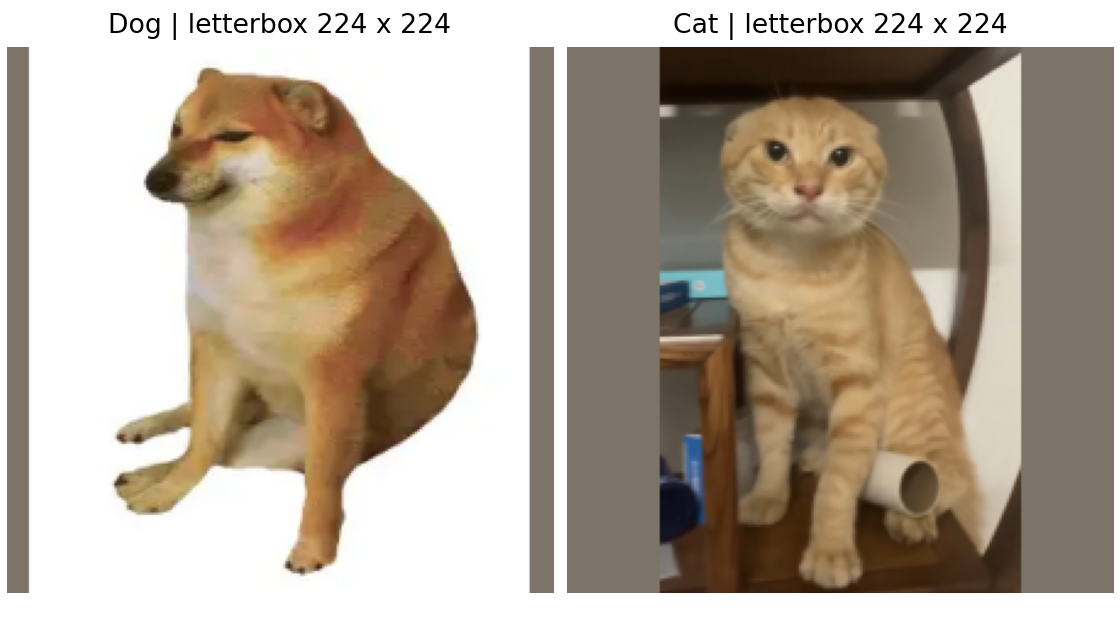

### Dog

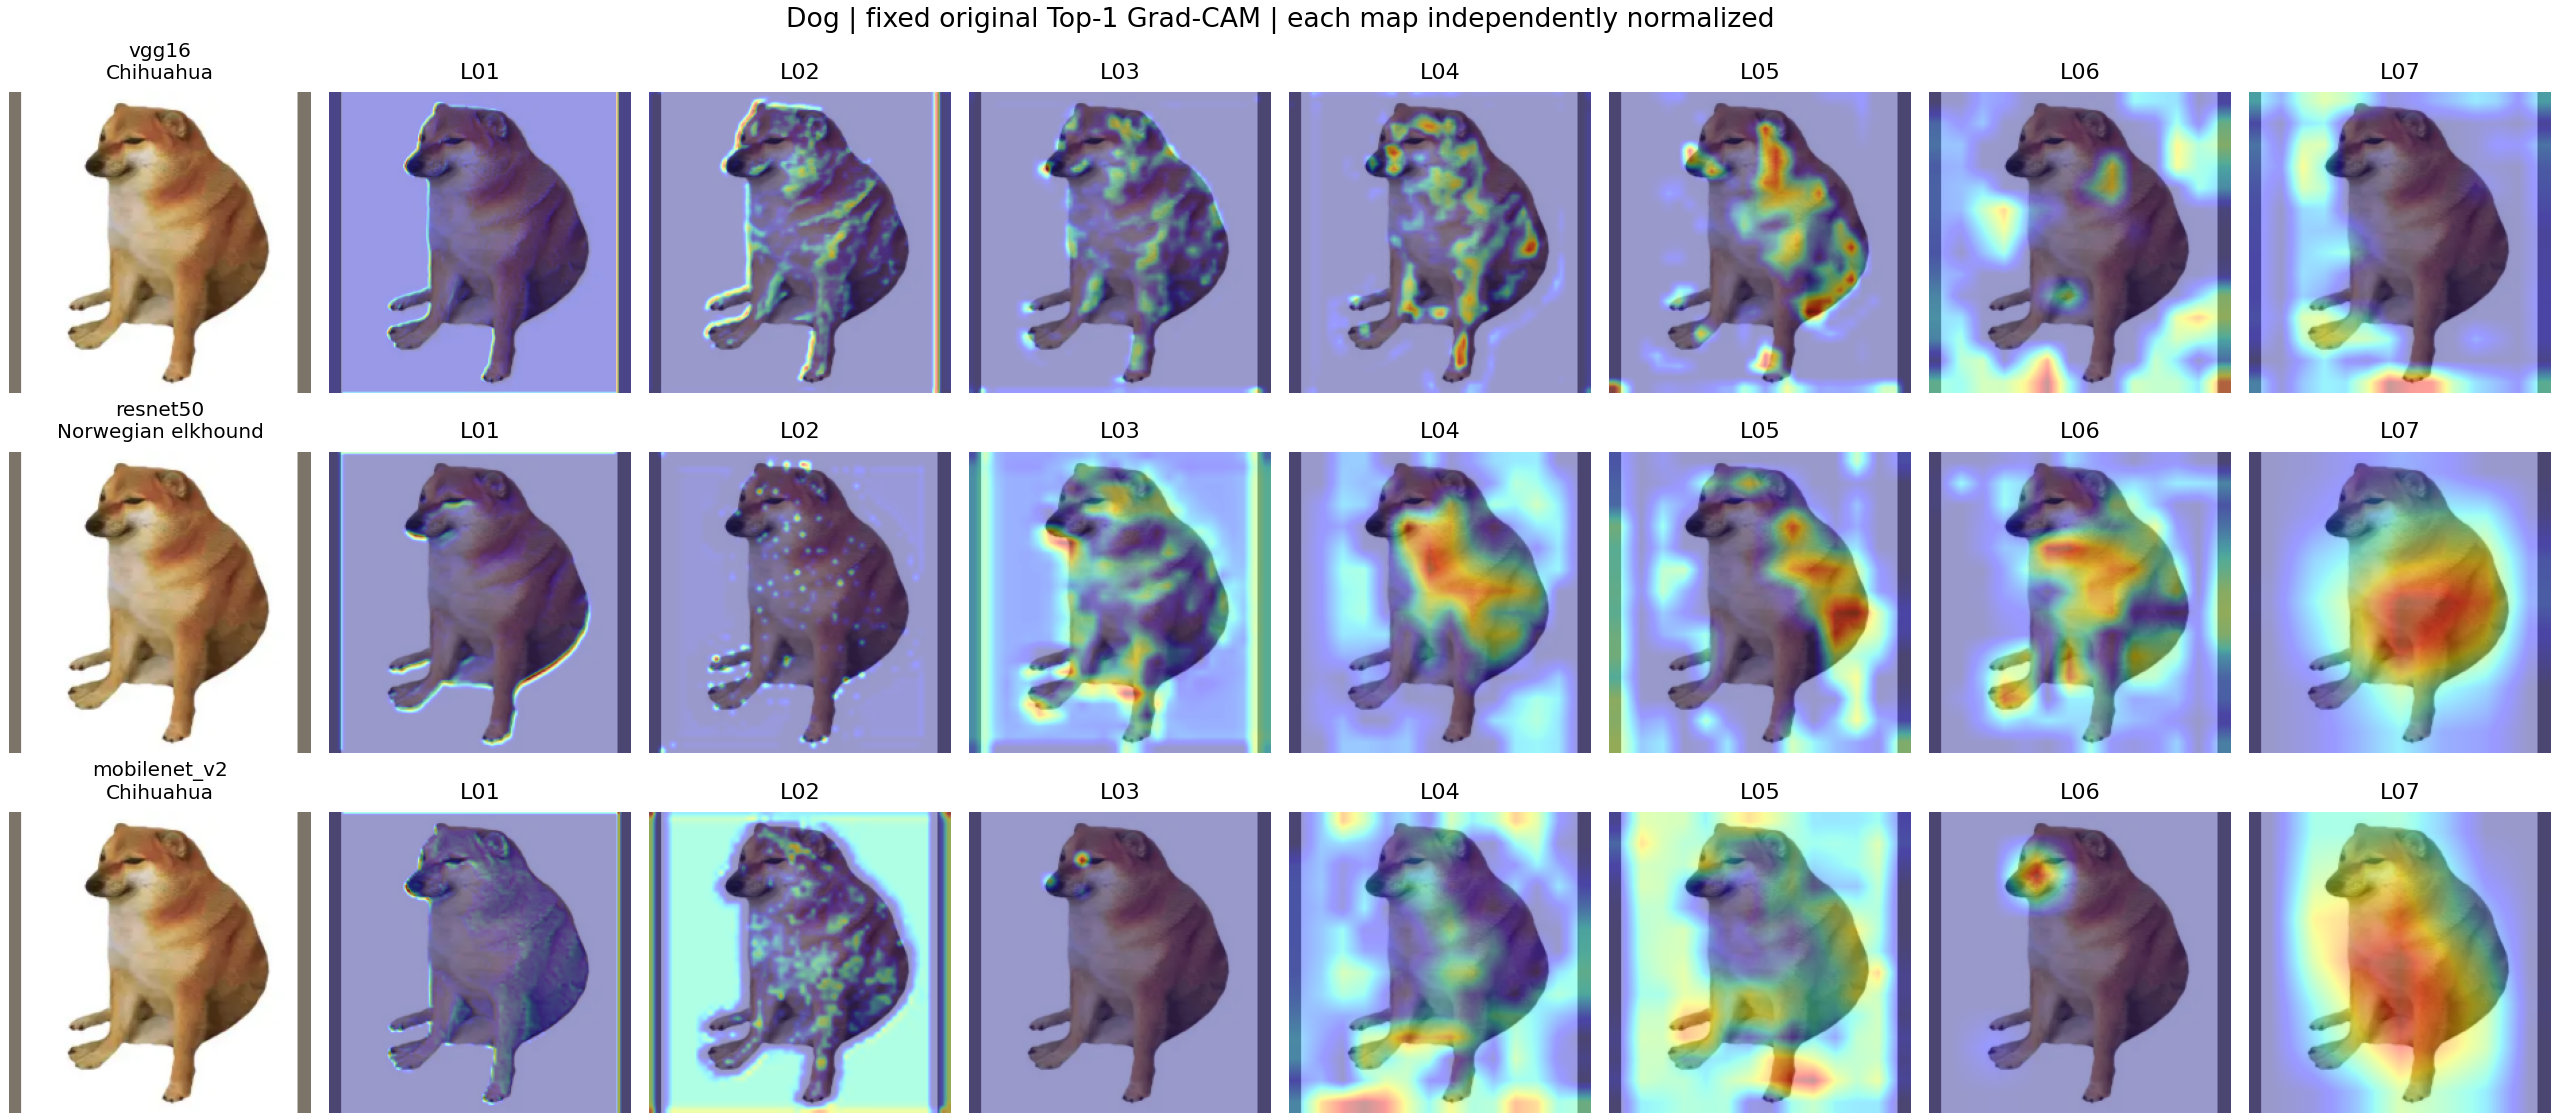

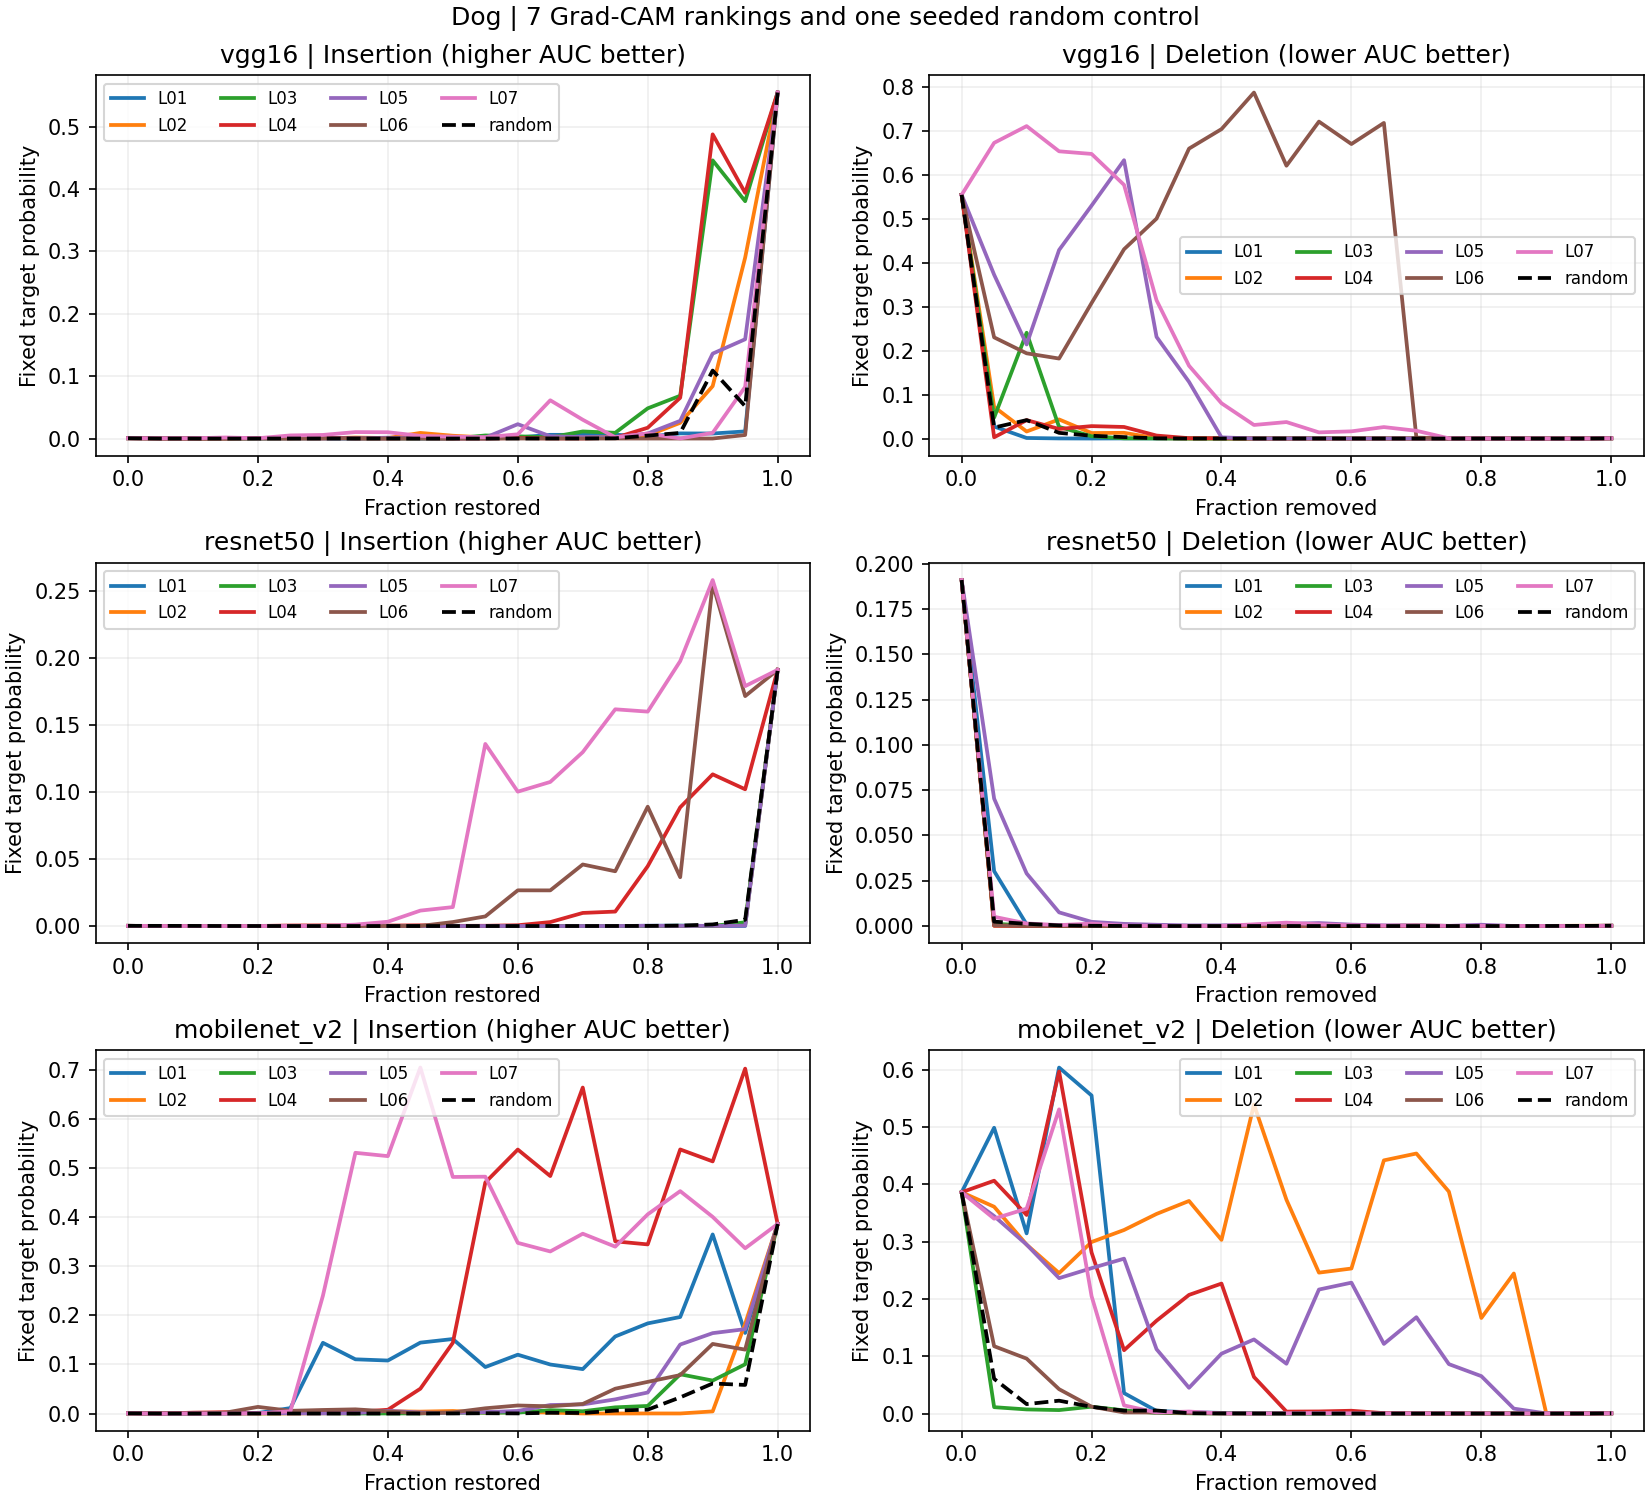

**vgg16 | Chihuahua**

,method,original_probability,insertion_auc,deletion_auc,insertion_gain_vs_random,deletion_gain_vs_random,all_zero
0,L01,0.5547,0.0164,0.0155,-0.0062,0.0029,False
1,L02,0.5547,0.0353,0.0218,0.0127,-0.0034,False
2,L03,0.5547,0.0627,0.0299,0.0401,-0.0115,False
3,L04,0.5547,0.0624,0.0204,0.0398,-0.0020,False
4,L05,0.5547,0.0323,0.1410,0.0096,-0.1226,False
5,L06,0.5547,0.0143,0.3504,-0.0084,-0.3320,False
6,L07,0.5547,0.0261,0.2122,0.0034,-0.1938,False
7,random,0.5547,0.0227,0.0184,0.0000,0.0000,False


**resnet50 | Norwegian elkhound**

,method,original_probability,insertion_auc,deletion_auc,insertion_gain_vs_random,deletion_gain_vs_random,all_zero
0,L01,0.191,0.0048,0.0064,-0.0003,-0.0014,False
1,L02,0.191,0.0049,0.0048,-0.0003,0.0002,False
2,L03,0.191,0.0049,0.0049,-0.0002,0.0001,False
3,L04,0.191,0.0235,0.0048,0.0184,0.0002,False
4,L05,0.191,0.0048,0.0107,-0.0003,-0.0057,False
5,L06,0.191,0.0399,0.0049,0.0348,0.0001,False
6,L07,0.191,0.0777,0.0055,0.0726,-0.0005,False
7,random,0.191,0.0051,0.0050,0.0000,0.0000,False


**mobilenet_v2 | Chihuahua**

,method,original_probability,insertion_auc,deletion_auc,insertion_gain_vs_random,deletion_gain_vs_random,all_zero
0,L01,0.3861,0.1168,0.1105,0.0986,-0.0947,False
1,L02,0.3861,0.0202,0.2920,0.0020,-0.2762,False
2,L03,0.3861,0.0244,0.0118,0.0062,0.0039,False
3,L04,0.3861,0.2507,0.1303,0.2325,-0.1145,False
4,L05,0.3861,0.0399,0.1483,0.0217,-0.1325,False
5,L06,0.3861,0.0382,0.0233,0.0200,-0.0075,False
6,L07,0.3861,0.3071,0.0825,0.2889,-0.0667,False
7,random,0.3861,0.0182,0.0158,0.0000,0.0000,False


### Cat

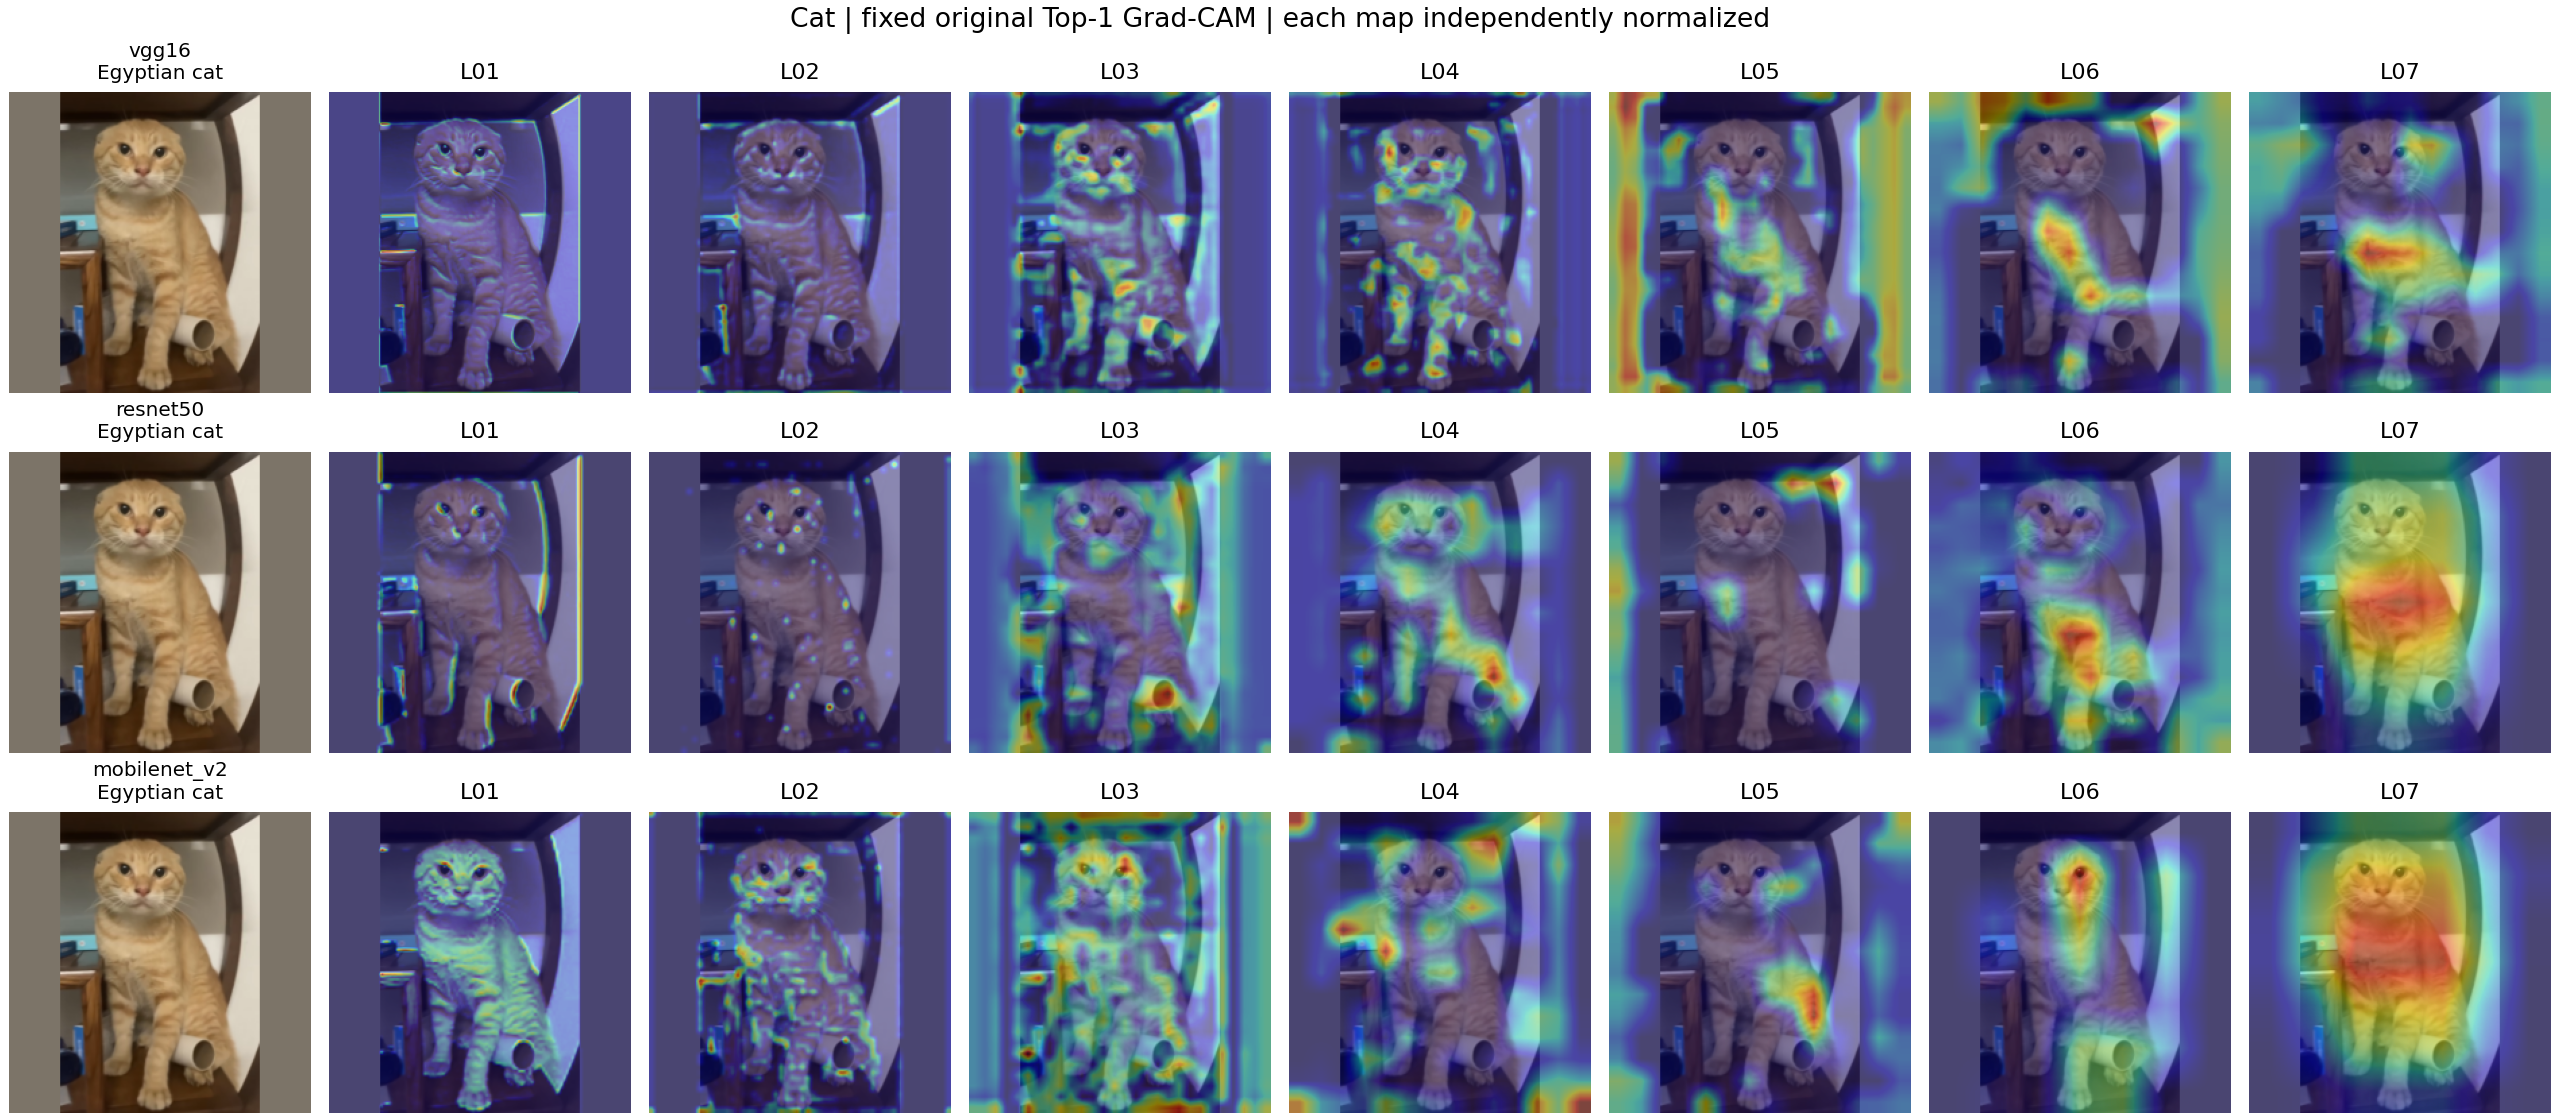

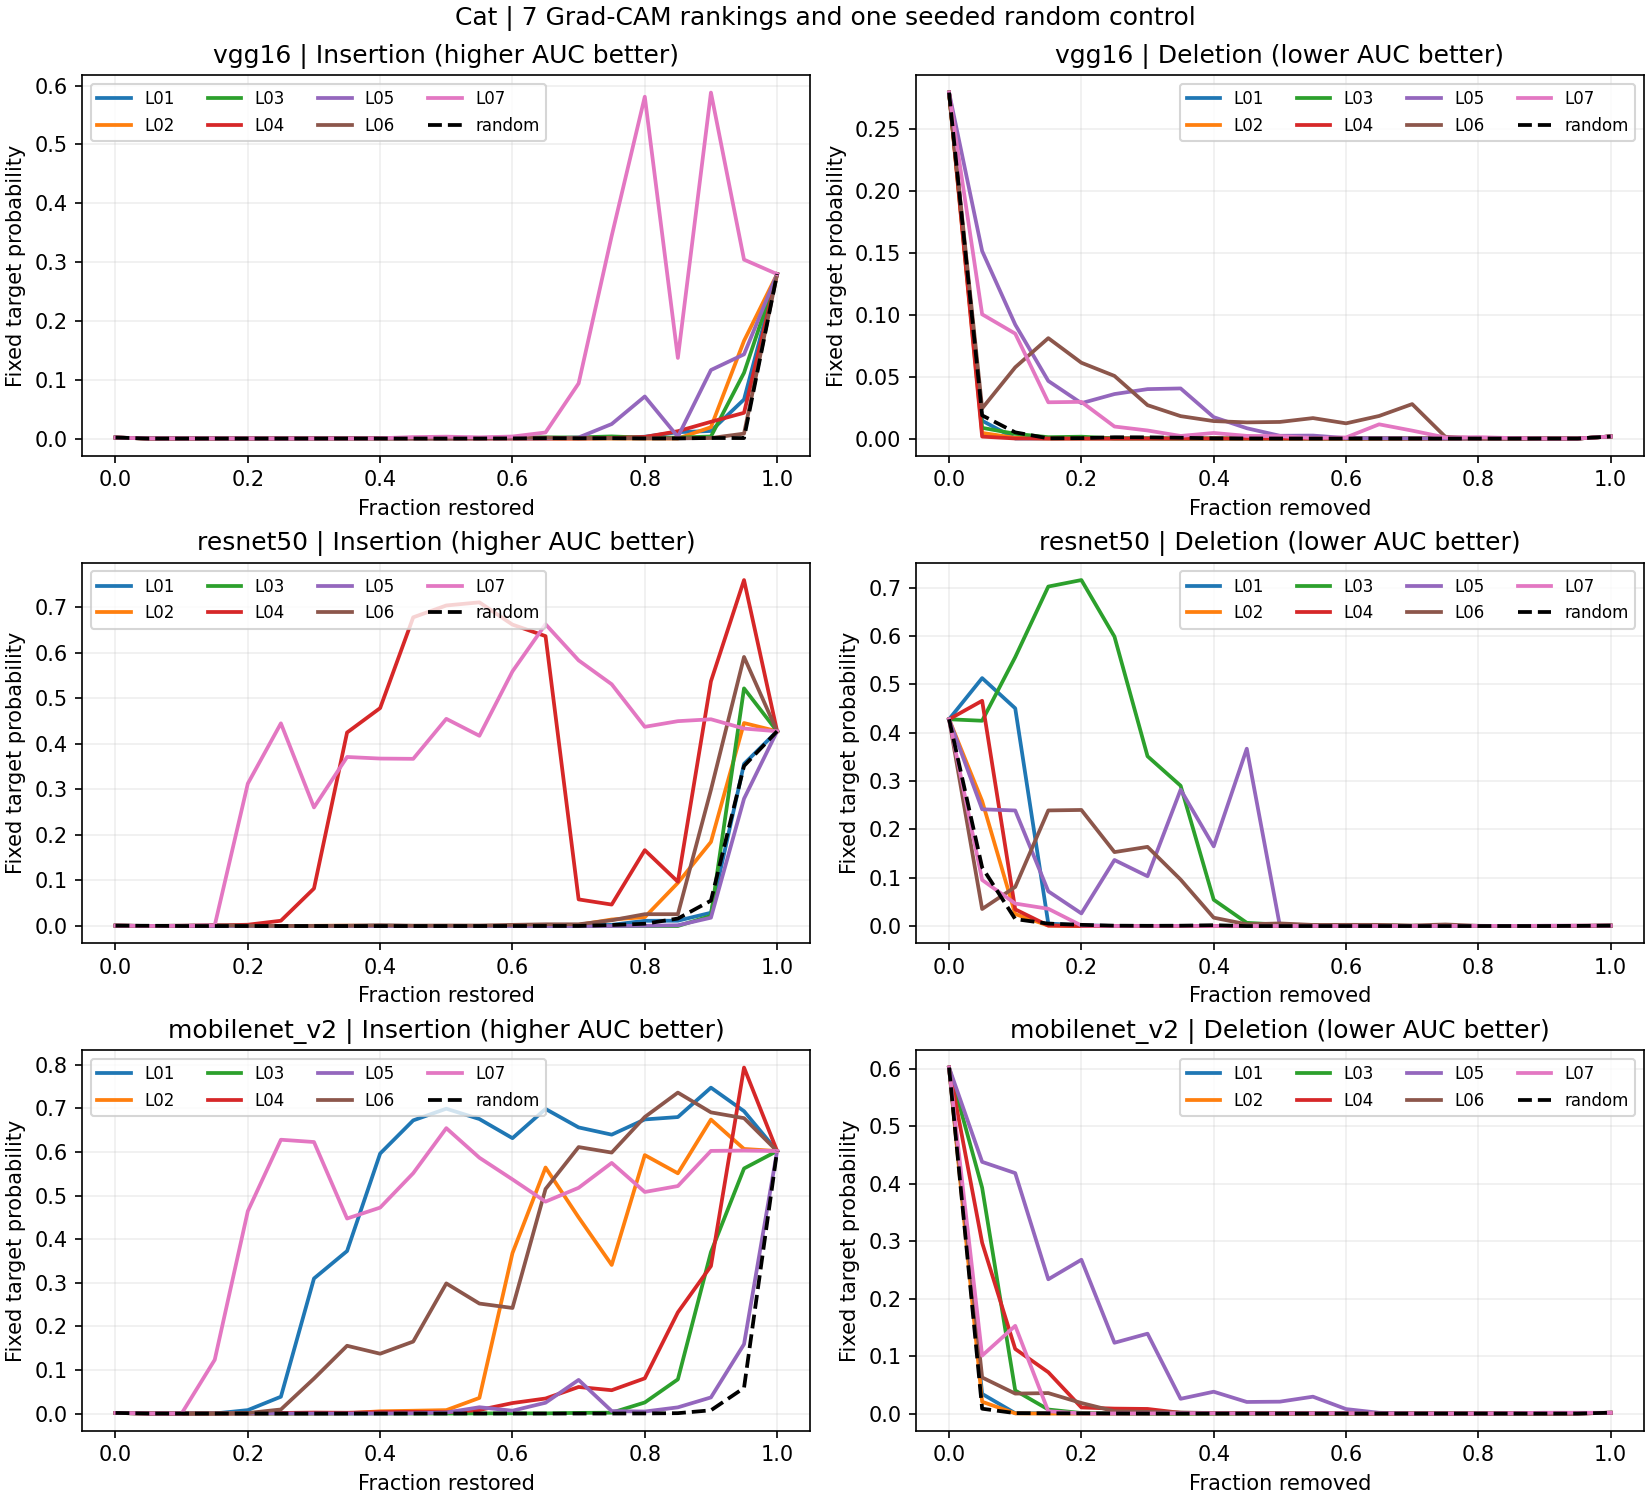

**vgg16 | Egyptian cat**

,method,original_probability,insertion_auc,deletion_auc,insertion_gain_vs_random,deletion_gain_vs_random,all_zero
0,L01,0.2795,0.0122,0.0078,0.0049,0.0006,False
1,L02,0.2795,0.0163,0.0073,0.0091,0.0011,False
2,L03,0.2795,0.0135,0.0078,0.0062,0.0006,False
3,L04,0.2795,0.0115,0.0071,0.0043,0.0013,False
4,L05,0.2795,0.0251,0.0303,0.0179,-0.0219,False
5,L06,0.2795,0.0079,0.0289,0.0007,-0.0205,False
6,L07,0.2795,0.1106,0.0217,0.1034,-0.0133,False
7,random,0.2795,0.0072,0.0084,0.0000,0.0000,False


**resnet50 | Egyptian cat**

,method,original_probability,insertion_auc,deletion_auc,insertion_gain_vs_random,deletion_gain_vs_random,all_zero
0,L01,0.4276,0.0314,0.0592,-0.0009,-0.0411,False
1,L02,0.4276,0.0489,0.0250,0.0166,-0.0069,False
2,L03,0.4276,0.0379,0.1960,0.0056,-0.1780,False
3,L04,0.4276,0.3136,0.0358,0.2813,-0.0177,False
4,L05,0.4276,0.0258,0.0925,-0.0065,-0.0744,False
5,L06,0.4276,0.0594,0.0630,0.0271,-0.0449,False
6,L07,0.4276,0.3662,0.0198,0.3338,-0.0018,False
7,random,0.4276,0.0323,0.0181,0.0000,0.0000,False


**mobilenet_v2 | Egyptian cat**

,method,original_probability,insertion_auc,deletion_auc,insertion_gain_vs_random,deletion_gain_vs_random,all_zero
0,L01,0.6023,0.4550,0.0169,0.4365,-0.0013,False
1,L02,0.6023,0.2254,0.0162,0.2069,-0.0006,False
2,L03,0.6023,0.0672,0.0372,0.0487,-0.0216,False
3,L04,0.6023,0.0972,0.0408,0.0787,-0.0251,False
4,L05,0.6023,0.0325,0.1033,0.0140,-0.0877,False
5,L06,0.6023,0.3078,0.0233,0.2894,-0.0077,False
6,L07,0.6023,0.4604,0.0283,0.4419,-0.0127,False
7,random,0.6023,0.0185,0.0156,0.0000,0.0000,False


In [3]:
RUN_CASE_EXPERIMENT=False
# Locate the original PNG bytes embedded in this notebook's metadata.
CASE_INPUTS=None
for notebook_path in list(Path.cwd().glob('*.ipynb'))+list(ROOT.glob('*.ipynb')):
    embedded=json.loads(notebook_path.read_text(encoding='utf-8')).get('metadata',{}).get('case_input_data')
    if embedded:
        CASE_INPUTS=embedded
        break
if CASE_INPUTS is None:
    raise RuntimeError('Save this notebook with its embedded case_input_data metadata before running.')
"""Two illustrative inputs, kept separate from the completed 50,000-image benchmark."""
import base64
import io


def case_letterbox(image):
    image=image.convert('RGB')
    ratio=min(224/image.width,224/image.height)
    size=(round(image.width*ratio),round(image.height*ratio))
    canvas=Image.new('RGB',(224,224),(124,116,104))
    resized=image.resize(size,Image.Resampling.BILINEAR)
    offset=((224-size[0])//2,(224-size[1])//2)
    canvas.paste(resized,offset)
    pixels=np.asarray(canvas).copy()
    tensor=torch.from_numpy(pixels).permute(2,0,1).float()/255
    tensor=(tensor-torch.tensor([.485,.456,.406])[:,None,None])/torch.tensor([.229,.224,.225])[:,None,None]
    return canvas,tensor,{'original_size':list(image.size),'resized_size':list(size),'offset':list(offset)}


def run_cat_dog_cases(case_inputs):
    folder=FULL/'cat_dog_cases';folder.mkdir(exist_ok=True)
    inputs=[];images=[];tensors=[]
    for item in case_inputs:
        raw=base64.b64decode(item['bytes_base64'])
        assert hashlib.sha256(raw).hexdigest()==item['sha256']
        original=folder/(item['id']+'_original.png');original.write_bytes(raw)
        with Image.open(io.BytesIO(raw)) as im:canvas,tensor,geometry=case_letterbox(im)
        canvas.save(folder/(item['id']+'_224.png'))
        inputs.append({'id':item['id'],'sha256':item['sha256'],**geometry})
        images.append(canvas);tensors.append(tensor)
    x=torch.stack(tensors).to(DEVICE,memory_format=torch.channels_last)
    rows=[];model_records=[];started=time.monotonic()
    # Small case study uses FP32 throughout, independently of full-run FP16 gates.
    torch.backends.cudnn.benchmark=False
    torch.backends.cudnn.deterministic=True
    torch.use_deterministic_algorithms(True,warn_only=True)
    for name,(builder,weights,layers) in SPECS.items():
        model=builder(weights=weights,progress=False).eval().to(DEVICE,memory_format=torch.channels_last)
        for parameter in model.parameters():parameter.requires_grad_(False)
        for module in model.modules():
            if isinstance(module,(torch.nn.ReLU,torch.nn.ReLU6)):module.inplace=False
        with warnings.catch_warnings(record=True) as logged:
            warnings.simplefilter('always')
            cams,targets,reference=collect_cams(model,x,layers)
        ranks,zero=rank_maps(cams,[1000000,1000001])
        curves=evaluate_curves(model,x,ranks,targets).cpu().numpy()
        assert np.max(np.abs(curves[:,:,0,-1]-reference.cpu().numpy()[:,None]))<1e-5
        assert np.allclose(curves[:,:,0,0],curves[:,:,1,-1],atol=1e-7)
        assert np.allclose(curves[:,:,0,-1],curves[:,:,1,0],atol=1e-7)
        for i,slot in torch.nonzero(zero,as_tuple=False).cpu().tolist():
            assert torch.equal(ranks[i,slot],ranks[i,7])
            assert np.allclose(curves[i,slot],curves[i,7],atol=1e-7)
        auc=np.trapezoid(curves.astype(np.float64),x=FRACTIONS,axis=-1)
        manual=((curves[...,1:].astype(np.float64)+curves[...,:-1])*np.diff(FRACTIONS)/2).sum(-1)
        assert np.max(np.abs(auc-manual))<1e-12
        up=torch.stack([F.interpolate(c[:,None],size=(224,224),mode='bilinear',align_corners=False)[:,0] for c in cams],dim=1)
        arrays={'curves':curves,'targets':targets.cpu().numpy(),'original_probability':reference.cpu().numpy(),
                'cams_224':up.cpu().numpy(),'all_zero':zero.cpu().numpy(),'fractions':FRACTIONS}
        for slot,cam in enumerate(cams):arrays[f'raw_cam_{slot+1:02d}']=cam.cpu().numpy()
        path=folder/(name+'.npz');np.savez_compressed(path,**arrays)
        for i,item in enumerate(inputs):
            for slot,method in enumerate(METHODS):
                rows.append({'image':item['id'],'model':name,'method':method,
                    'target_id':int(targets[i]),'target':weights.meta['categories'][int(targets[i])],
                    'original_probability':float(reference[i]),'insertion_auc':float(auc[i,slot,0]),
                    'deletion_auc':float(auc[i,slot,1]),'insertion_gain_vs_random':float(auc[i,slot,0]-auc[i,7,0]),
                    'deletion_gain_vs_random':float(auc[i,7,1]-auc[i,slot,1]),
                    'all_zero':bool(zero[i,slot]) if slot<7 else False})
        model_records.append({'model':name,'sha256':digest(path),'targets':targets.cpu().tolist(),
            'original_probability':reference.cpu().tolist(),'zero_maps':int(zero.sum()),'precision':'FP32',
            'layers':layers,'weights':str(weights),
            'backward_warnings':sorted(set(str(w.message).split(' (')[0] for w in logged))})
        print('Case study completed:',name,flush=True)
        del model,cams,ranks,zero,up,arrays;gc.collect();torch.cuda.empty_cache()
    pd.DataFrame(rows).to_csv(folder/'summary.csv',index=False)
    write_json(folder/'complete.json',{'complete':True,'inputs':inputs,'models':model_records,
        'n_images':2,'gradcam_combinations':42,'random_controls':6,'steps':21,'fixed_original_top1':True,
        'preprocessing':'bilinear aspect-preserving resize, centered letterbox 224, RGB(124,116,104), ImageNet normalization',
        'baseline':'zero normalized tensor (ImageNet mean RGB)','seed':SEED,'random_row_ids':[1000000,1000001],
        'included_in_full_validation_statistics':False,'two_sample_cka_computed':False,
        'seconds':time.monotonic()-started,'finished_at':time.strftime('%Y-%m-%dT%H:%M:%S%z'),
        'summary_sha256':digest(folder/'summary.csv'),
        'audit':'fixed endpoints, zero-map random equivalence, finite curves and manual trapezoidal AUC checked'})
    plot_cat_dog_cases()


def plot_cat_dog_cases():
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    folder=FULL/'cat_dog_cases'
    table=pd.read_csv(folder/'summary.csv')
    images=[np.array(Image.open(folder/(key+'_224.png')).convert('RGB')) for key in ['dog','cat']]
    fig,axes=plt.subplots(1,2,figsize=(7,4),constrained_layout=True)
    for i,key in enumerate(['dog','cat']):
        axes[i].imshow(images[i]);axes[i].set_title(key.title()+' | letterbox 224 x 224');axes[i].axis('off')
    fig.savefig(folder/'case_inputs.png',dpi=160);plt.close(fig)
    for i,key in enumerate(['dog','cat']):
        fig,axes=plt.subplots(3,8,figsize=(16,7),constrained_layout=True)
        for row,name in enumerate(SPECS):
            record=table[(table.image==key)&(table.model==name)].iloc[0]
            axes[row,0].imshow(images[i]);axes[row,0].set_title(name+'\n'+record.target,fontsize=9)
            with np.load(folder/(name+'.npz')) as data:
                for slot in range(7):
                    cam=data['cams_224'][i,slot];peak=float(cam.max())
                    ax=axes[row,slot+1];ax.imshow(images[i]);ax.imshow(cam/max(peak,1e-12),cmap='jet',alpha=.4,vmin=0,vmax=1)
                    ax.set_title(f'L{slot+1:02d}'+(' | zero' if peak==0 else ''),fontsize=10)
            for ax in axes[row]:ax.axis('off')
        fig.suptitle(key.title()+' | fixed original Top-1 Grad-CAM | each map independently normalized')
        fig.savefig(folder/(key+'_cams.png'),dpi=160);plt.close(fig)
        fig,axes=plt.subplots(3,2,figsize=(11,10),constrained_layout=True)
        for row,name in enumerate(SPECS):
            with np.load(folder/(name+'.npz')) as data:curves=data['curves'][i]
            for metric in range(2):
                ax=axes[row,metric]
                for slot,method in enumerate(METHODS):
                    ax.plot(FRACTIONS,curves[slot,metric],label=method,
                        color='black' if slot==7 else plt.cm.tab10(slot),ls='--' if slot==7 else '-',lw=1.8)
                ax.set_title(name+' | '+('Insertion (higher AUC better)' if metric==0 else 'Deletion (lower AUC better)'))
                ax.set_xlabel('Fraction restored' if metric==0 else 'Fraction removed')
                ax.set_ylabel('Fixed target probability');ax.grid(alpha=.2);ax.legend(ncol=4,fontsize=8)
        fig.suptitle(key.title()+' | 7 Grad-CAM rankings and one seeded random control')
        fig.savefig(folder/(key+'_curves.png'),dpi=150);plt.close(fig)



case_folder=FULL/'cat_dog_cases'
if RUN_CASE_EXPERIMENT:
    run_cat_dog_cases(CASE_INPUTS)
case_record=json.loads((case_folder/'complete.json').read_text(encoding='utf-8'))
assert case_record['complete'] and case_record['n_images']==2
assert not case_record['included_in_full_validation_statistics']
for expected,saved in zip(CASE_INPUTS,case_record['inputs']):
    assert expected['sha256']==saved['sha256']
    assert digest(case_folder/(expected['id']+'_original.png'))==expected['sha256']
for record in case_record['models']:
    assert digest(case_folder/(record['model']+'.npz'))==record['sha256']
assert digest(case_folder/'summary.csv')==case_record['summary_sha256']
case_table=pd.read_csv(case_folder/'summary.csv')
assert len(case_table)==48
display(pd.DataFrame(case_record['inputs']))
display(pd.DataFrame([{'model':r['model'],'precision':r['precision'],'zero_maps':r['zero_maps'],
    'backward_warnings':r.get('backward_warnings',[])} for r in case_record['models']]))
display(DisplayImage(filename=str(case_folder/'case_inputs.png')))
for image_id in ['dog','cat']:
    display(Markdown('### '+image_id.title()))
    display(DisplayImage(filename=str(case_folder/(image_id+'_cams.png'))))
    display(DisplayImage(filename=str(case_folder/(image_id+'_curves.png'))))
    for model_name in SPECS:
        sub=case_table[(case_table.image==image_id)&(case_table.model==model_name)]
        display(Markdown('**'+model_name+' | '+str(sub.iloc[0].target)+'**'))
        display(sub[['method','original_probability','insertion_auc','deletion_auc',
            'insertion_gain_vs_random','deletion_gain_vs_random','all_zero']].round(4).reset_index(drop=True))


In [4]:
case_lines=[]
for (image_id,model_name),sub in case_table.groupby(['image','model'],sort=False):
    layers=sub[sub.method!='random']
    ins=layers.loc[layers.insertion_auc.idxmax()]
    dele=layers.loc[layers.deletion_auc.idxmin()]
    case_lines.append(f"**{image_id} / {model_name}**: target={sub.iloc[0].target}; best insertion {ins.method}={ins.insertion_auc:.4f}; best deletion {dele.method}={dele.deletion_auc:.4f}; layers better than random: insertion {int((layers.insertion_gain_vs_random>0).sum())}/7, deletion {int((layers.deletion_gain_vs_random>0).sum())}/7.")
display(Markdown('\n\n'.join(case_lines)))

display(Markdown('Perturbation probabilities need not change monotonically. Compare whole-curve AUC rather than selected endpoints. The best insertion and deletion layers can differ; report both metrics. With two inputs and one seeded random ranking per input, no population significance is claimed, and raw probabilities are not used to rank different models.'))


**dog / vgg16**: target=Chihuahua; best insertion L03=0.0627; best deletion L01=0.0155; layers better than random: insertion 5/7, deletion 1/7.

**cat / vgg16**: target=Egyptian cat; best insertion L07=0.1106; best deletion L04=0.0071; layers better than random: insertion 7/7, deletion 4/7.

**dog / resnet50**: target=Norwegian elkhound; best insertion L07=0.0777; best deletion L02=0.0048; layers better than random: insertion 3/7, deletion 4/7.

**cat / resnet50**: target=Egyptian cat; best insertion L07=0.3662; best deletion L07=0.0198; layers better than random: insertion 5/7, deletion 0/7.

**dog / mobilenet_v2**: target=Chihuahua; best insertion L07=0.3071; best deletion L03=0.0118; layers better than random: insertion 7/7, deletion 1/7.

**cat / mobilenet_v2**: target=Egyptian cat; best insertion L07=0.4604; best deletion L02=0.0162; layers better than random: insertion 7/7, deletion 0/7.

Perturbation probabilities need not change monotonically. Compare whole-curve AUC rather than selected endpoints. The best insertion and deletion layers can differ; report both metrics. With two inputs and one seeded random ranking per input, no population significance is claimed, and raw probabilities are not used to rank different models.

## B. From two cases to complete ImageNet validation

Cases show what happens on particular inputs, not the population pattern. We now keep the same models, weights, and seven taps and evaluate representation similarity and attribution ranking across 50,000 validation images and 1,000 classes.

Cases use the team's full-image letterbox; the benchmark retains the weights' standard resize/center-crop. Case scoring is FP32, while benchmark scoring uses empirically gated FP16 with FP32 fallbacks. These protocol differences prevent a strictly controlled sample-size comparison; discrepancies cannot be attributed solely to sample count. Cases are excluded from full-data means/bootstrap, and no two-input CKA is computed.
The existing full-validation methods, implementation, figures, and conclusions follow unchanged.


## 2. Data and seven feature taps

Only the pinned official validation split is downloaded: 14 parquet shards, approximately 6.23 GiB, not the training set.
Accept ImageNet access conditions and authenticate locally with `hf auth login`; credentials are not embedded or printed.
Verify shard SHA256, decoding, exactly 50,000 records, and 50 images per class. Preserve every official row, including source duplicates, and report duplicate counts rather than silently excluding them.
RGB preprocessing uses bilinear shorter-edge resize to 256, a 224 center crop, and ImageNet mean/std normalization. Seeded final ordering is fixed.

A tap is a sampling location; a hook records its output. All taps are raw Conv2d outputs before subsequent BatchNorm/ReLU and, for ResNet, before residual addition.
Equal slots do not imply equal semantics or receptive fields. Full-channel GAP maps `[N,C,H,W]` to `[N,C]`, discarding spatial arrangement.
Immediate clones prevent inplace mutation. Features are stored in recoverable disk arrays rather than retaining all high-resolution feature maps.


In [5]:
def prepare_full_dataset():
    manifest_path=FULL/'data/manifest.json'
    if manifest_path.exists():
        m=json.loads(manifest_path.read_text(encoding='utf-8'))
        assert len(m['images'])==N_FULL and m['revision']==REVISION
        assert np.bincount([r['label'] for r in m['images']],minlength=1000).tolist()==[50]*1000
        if all((ROOT/r['path']).exists() for r in m['images']):return m
        print('Manifest retained as evidence; image cache absent. Rebuilding authorized data cache.',flush=True)
    if not get_token():raise RuntimeError('Local authorized Hugging Face login is required.')
    parquet_dir=FULL/'data/parquet';parquet_dir.mkdir(parents=True,exist_ok=True)
    info=HfApi().dataset_info(REPO,revision=REVISION,files_metadata=True,token=True)
    shards=sorted([s for s in info.siblings if 'validation-' in s.rfilename and s.rfilename.endswith('.parquet')],key=lambda s:s.rfilename)
    assert len(shards)==14
    expected=[]
    for s in shards:
        lfs=s.lfs
        sha=lfs.get('sha256') if isinstance(lfs,dict) else getattr(lfs,'sha256',None)
        expected.append({'file':s.rfilename,'size':s.size,'sha256':sha})
    write_json(FULL/'data/download_manifest.json',{'repo':REPO,'revision':REVISION,'shards':expected,
          'bytes_total':sum(x['size'] for x in expected)})
    progress('download',0,len(shards),f"Official validation parquet: {sum(x['size'] for x in expected)/1024**3:.2f} GiB")
    def fetch(item):
        final=parquet_dir/Path(item['file']).name
        if not final.exists() or final.stat().st_size!=item['size']:
            import requests
            url=f'https://huggingface.co/datasets/{REPO}/resolve/{REVISION}/{item["file"]}'
            partial=final.with_name(final.name+'.partial')
            for attempt in range(8):
                try:
                    if partial.exists() and partial.stat().st_size==item['size']:
                        if not item['sha256'] or digest(partial)==item['sha256']:
                            partial.replace(final);break
                        partial.rename(partial.with_name(partial.name+f'.corrupt.{int(time.time())}'))
                    offset=partial.stat().st_size if partial.exists() else 0
                    headers={'Authorization':'Bearer '+get_token()}
                    if offset:headers['Range']=f'bytes={offset}-'
                    # requests removes Authorization when redirecting to the CDN host.
                    with requests.get(url,headers=headers,stream=True,timeout=(20,30)) as response:
                        response.raise_for_status()
                        resume=response.status_code==206 and offset>0
                        if resume:assert response.headers.get('Content-Range','').startswith(f'bytes {offset}-')
                        count=offset if resume else 0;next_log=count+64*1024**2
                        with partial.open('ab' if resume else 'wb') as output:
                            for block in response.iter_content(1024**2):
                                if not block:continue
                                output.write(block);count+=len(block)
                                if count>=next_log:
                                    print('Download',final.name,round(count/1024**2),'MiB',flush=True)
                                    next_log=count+64*1024**2
                    assert partial.stat().st_size==item['size']
                    actual=digest(partial)
                    if item['sha256']:assert actual==item['sha256']
                    partial.replace(final);break
                except Exception as exc:
                    print('Retry official shard',final.name,'attempt',attempt+1,'error',type(exc).__name__,flush=True)
                    if attempt==7:raise RuntimeError('Official validation shard download failed: '+final.name) from None
                    time.sleep(min(2**attempt,16))
        assert final.stat().st_size==item['size']
        actual=digest(final)
        if item['sha256']:assert actual==item['sha256'],final.name
        return final,actual
    completed=0;verified={}
    with ThreadPoolExecutor(max_workers=3) as pool:
        futures={pool.submit(fetch,x):x for x in expected}
        for future in as_completed(futures):
            path,sha=future.result();verified[path.name]=sha;completed+=1
            progress('download',completed,14,path.name)
    images_dir=FULL/'data/images';images_dir.mkdir(exist_ok=True)
    records=[];bad=[];seen={};index=0;started=time.monotonic()
    for item in expected:
        path=parquet_dir/Path(item['file']).name
        for batch in pq.ParquetFile(path).iter_batches(batch_size=128,columns=['image','label']):
            for row in batch.to_pylist():
                raw=row['image']['bytes'];label=int(row['label'])
                sha=hashlib.sha256(raw).hexdigest()
                image_path=images_dir/f'{index:05d}.img'
                if not image_path.exists() or image_path.stat().st_size!=len(raw):image_path.write_bytes(raw)
                try:
                    with Image.open(image_path) as im:
                        im.convert('RGB').load();width,height=im.size
                except (OSError,ValueError) as exc:
                    bad.append({'row':index,'error':str(exc)})
                    raise RuntimeError('A validation image cannot be decoded; no silent exclusion.') from exc
                records.append({'image_id':f'imagenet-validation-{index:05d}','row_index':index,
                    'label':label,'sha256':sha,'path':str(image_path.relative_to(ROOT)),
                    'width':width,'height':height})
                seen[sha]=seen.get(sha,0)+1;index+=1
                if index%2500==0:progress('decode',index,N_FULL,'Validated original JPEG bytes',seconds=time.monotonic()-started)
    assert index==N_FULL
    assert np.bincount([r['label'] for r in records],minlength=1000).tolist()==[50]*1000
    old_path=ROOT/'cka_study/imagenet_subset/manifest.json'
    if old_path.exists():
        old=json.loads(old_path.read_text(encoding='utf-8'))
        for r in old['images']:assert records[r['row_index']]['sha256']==r['sha256']
    # Preserve all official rows, including any source duplicates; report, do not remove.
    np.random.default_rng(SEED).shuffle(records)
    m={'repo':REPO,'revision':REVISION,'split':'validation','selection':'entire official validation split; seeded final order',
       'n':N_FULL,'classes':1000,'per_class':50,'unique_byte_hashes':len(seen),
       'duplicate_byte_rows':N_FULL-len(seen),'invalid_images':bad,'parquet_sha256':verified,'images':records}
    write_json(manifest_path,m)
    progress('data_ready',N_FULL,N_FULL,'Complete official validation set verified')
    return m


class FullImages(torch.utils.data.Dataset):
    def __init__(self,manifest):self.records=manifest['images']
    def __len__(self):return len(self.records)
    def __getitem__(self,index):
        r=self.records[index]
        with Image.open(ROOT/r['path']) as im:x=TRANSFORM(im.convert('RGB'))
        return x,index

def model_resources():
    result={}
    for name,(_,weights,layers) in SPECS.items():
        p=Path(torch.hub.get_dir())/'checkpoints'/weights.url.rsplit('/',1)[1]
        if not p.exists():
            torch.hub.load_state_dict_from_url(weights.url,model_dir=str(p.parent),check_hash=True,progress=False,map_location='cpu')
        sha=digest(p);assert sha.startswith(p.stem.rsplit('-',1)[1])
        result[name]={'weights':str(weights),'sha256':sha,'layers':layers,'url':weights.url}
    return result

def extract_features(manifest,resources):
    dataset=FullImages(manifest);features={};metadata={}
    for name,(builder,weights,layers) in SPECS.items():
        folder=FULL/'features'/name;folder.mkdir(parents=True,exist_ok=True)
        meta_path=folder/'metadata.json'
        signature={'engine':CONFIG['engine_version'],'data':digest(FULL/'data/manifest.json'),
                   'model':resources[name],'precision':'FP32, channels_last, TF32 disabled',
                   'representation':'all-channel raw Conv2d GAP before subsequent BN/ReLU',
                   'torch':torch.__version__,'torchvision':torchvision.__version__}
        if meta_path.exists():
            old=json.loads(meta_path.read_text(encoding='utf-8'))
            assert old['signature']==signature
            present=all((folder/f'L{i:02d}.npy').exists() for i in range(1,8))
            if old.get('complete') and present:
                features[name]=[np.load(folder/f'L{i:02d}.npy',mmap_mode='r') for i in range(1,8)]
                metadata[name]=old;continue
            offset=old['done'] if present and not old.get('complete') else 0
        else:offset=0
        model=builder(weights=weights,progress=False).eval().to(DEVICE,memory_format=torch.channels_last)
        for p in model.parameters():p.requires_grad_(False)
        modules=dict(model.named_modules());channels=[modules[layer].out_channels for layer in layers]
        arrays=[np.lib.format.open_memmap(folder/f'L{i+1:02d}.npy',mode='r+' if offset else 'w+',
                    dtype=np.float32,shape=(N_FULL,c)) for i,c in enumerate(channels)]
        current={};handles=[];shapes={}
        def capture(slot):
            def hook(module,inputs,output):
                shapes[slot]=list(output.shape[1:])
                current[slot]=output.detach().clone().mean((2,3)).float().cpu().numpy()
            return hook
        for i,layer in enumerate(layers):handles.append(modules[layer].register_forward_hook(capture(i)))
        loader=torch.utils.data.DataLoader(torch.utils.data.Subset(dataset,range(offset,N_FULL)),
            batch_size=32,shuffle=False,num_workers=0,pin_memory=True)
        started=time.monotonic();done=offset
        try:
            with torch.no_grad():
                for x,idx in loader:
                    current.clear();out=model(x.to(DEVICE,non_blocking=True,memory_format=torch.channels_last))
                    assert torch.isfinite(out).all().item()
                    indices=idx.numpy()
                    assert np.array_equal(indices,np.arange(done,done+len(indices)))
                    for i,a in enumerate(arrays):
                        assert np.isfinite(current[i]).all();a[indices]=current[i]
                    done+=len(indices)
                    if done%512==0 or done==N_FULL:
                        for a in arrays:a.flush()
                        write_json(meta_path,{'signature':signature,'complete':False,'done':done,
                            'channels':channels,'raw_shapes':shapes})
                        progress('features_'+name,done,N_FULL,elapsed_s=time.monotonic()-started)
            final={'signature':signature,'complete':True,'done':done,'channels':channels,'raw_shapes':shapes,
                   'sha256':{f'L{i+1:02d}':digest(folder/f'L{i+1:02d}.npy') for i in range(7)}}
            write_json(meta_path,final);metadata[name]=final
        finally:
            for h in handles:h.remove()
            del model,current,arrays;gc.collect();torch.cuda.empty_cache()
        features[name]=[np.load(folder/f'L{i:02d}.npy',mmap_mode='r') for i in range(1,8)]
    return features,metadata


## 3. Scalable exact Linear CKA

After feature centering, `CKA=||Xc.T@Yc||F²/(||Xc.T@Xc||F*||Yc.T@Yc||F)`.
The Frobenius norm is the square root of summed squared entries. Rows correspond to the same images; column counts may differ.
Feature-space covariance is exactly equivalent to the Gram formulation without allocating any 50,000-by-50,000 matrix.
This is ordinary, non-debiased CKA, not a mean of minibatch CKA scores.

All 7-by-7 combinations are compared. Balanced subsets with 1, 5, 10, 25, and 50 images per class probe scale sensitivity; ten one-sided row mismatches provide controls.
Nine small real-feature combinations are independently recomputed using Gram arithmetic. High CKA concerns pooled sample relationships, not accuracy, causal evidence, or complete spatial equivalence.


In [6]:
def covariance_cka(features,indices=None,permutations=None):
    boundaries={};tensors={};norms={}
    with torch.no_grad():
        for name,values in features.items():
            selected=[np.asarray(x if indices is None else x[indices]) for x in values]
            joined=np.concatenate(selected,axis=1)
            x=torch.from_numpy(joined).to(DEVICE,dtype=torch.float64)
            x-=x.mean(0,keepdim=True)
            boundaries[name]=np.cumsum([0]+[v.shape[1] for v in values])
            tensors[name]=x
            b=boundaries[name];norm=[]
            for i in range(7):
                z=x[:,b[i]:b[i+1]];cov=z.T@z;norm.append(torch.linalg.matrix_norm(cov))
            norms[name]=torch.stack(norm)
            del joined,selected,cov
        names=list(features);pairs=[(names[0],names[1]),(names[0],names[2]),(names[1],names[2])]
        def calculate(permutation=None):
            result={}
            for a,b in pairs:
                y=tensors[b] if permutation is None else tensors[b].index_select(0,permutation)
                cov=tensors[a].T@y
                scores=torch.empty((7,7),device=DEVICE,dtype=torch.float64)
                ba,bb=boundaries[a],boundaries[b]
                for i in range(7):
                    for j in range(7):
                        block=cov[ba[i]:ba[i+1],bb[j]:bb[j+1]]
                        scores[i,j]=block.square().sum()/(norms[a][i]*norms[b][j])
                result[(a,b)]=scores.cpu().numpy()
                del cov,y
            return result
        primary=calculate()
        controls=[]
        for repeat in range(permutations or 0):
            perm=np.random.default_rng(SEED+1000+repeat).permutation(len(next(iter(tensors.values()))))
            controls.append(calculate(torch.from_numpy(perm).to(DEVICE)))
            progress('cka_mismatch',repeat+1,permutations,'Exact feature-space calculation')
        del tensors,norms;gc.collect();torch.cuda.empty_cache()
    return primary,controls

def run_cka(manifest,features):
    folder=FULL/'results';folder.mkdir(exist_ok=True)
    path=folder/'cka_results.npz'
    if path.exists() and (folder/'cka_complete.json').exists():return
    # Small-N independent Gram check, never allocate a 50,000 x 50,000 matrix.
    probe=np.arange(200);check,_=covariance_cka(features,probe)
    audit=[]
    for (a,b),m in check.items():
        for i in [0,3,6]:
            x=np.asarray(features[a][i][probe],np.float64);y=np.asarray(features[b][i][probe],np.float64)
            x-=x.mean(0);y-=y.mean(0);k=x@x.T;l=y@y.T
            reference=float((k*l).sum()/np.linalg.norm(k)/np.linalg.norm(l))
            error=abs(reference-m[i,i]);assert error<1e-9
            audit.append({'a':a,'b':b,'slot':i+1,'error':error})
    sizes=[1000,5000,10000,25000,50000];labels=np.array([r['label'] for r in manifest['images']])
    stability={};primary=None;controls=None
    for n in sizes:
        per_class=n//1000
        indices=np.concatenate([np.flatnonzero(labels==c)[:per_class] for c in range(1000)])
        assert len(indices)==n
        matrices,mismatches=covariance_cka(features,indices,permutations=10 if n==N_FULL else None)
        for pair,matrix in matrices.items():stability[(*pair,n)]=matrix
        if n==N_FULL:primary=matrices;controls=mismatches
        progress('cka_size',n,N_FULL,'Balanced per-class subsample')
    rows=[];control_rows=[];values={}
    for (a,b),m in primary.items():
        values[f'{a}__{b}']=m
        for i in range(7):
            for j in range(7):
                rows.append({'model_a':a,'slot_a':i+1,'module_a':SPECS[a][2][i],
                    'model_b':b,'slot_b':j+1,'module_b':SPECS[b][2][j],'cka':float(m[i,j]),'n':N_FULL})
        for n in sizes:
            values[f'{a}__{b}__n{n}']=stability[(a,b,n)]
        for r,control in enumerate(controls):values[f'{a}__{b}__shuffle{r}']=control[(a,b)]
    for (a,b,n),m in stability.items():
        for i in range(7):
            for j in range(7):control_rows.append({'kind':'balanced_size','a':a,'b':b,'n':n,'i':i+1,'j':j+1,'repeat':0,'cka':float(m[i,j])})
    for r,control in enumerate(controls):
        for (a,b),m in control.items():
            for i in range(7):
                for j in range(7):control_rows.append({'kind':'mismatch','a':a,'b':b,'n':N_FULL,'i':i+1,'j':j+1,'repeat':r+1,'cka':float(m[i,j])})
    pd.DataFrame(rows).to_csv(folder/'cka_main.csv',index=False)
    pd.DataFrame(control_rows).to_csv(folder/'cka_controls.csv',index=False)
    pd.DataFrame(audit).to_csv(folder/'cka_numeric_audit.csv',index=False)
    np.savez(path,**values)
    write_json(folder/'cka_complete.json',{'complete':True,'n':N_FULL,'scores':147,'sizes':sizes,
          'mismatches':10,'numeric_audit_max_error':max(r['error'] for r in audit),
          'method':CONFIG['cka'],'results_sha256':digest(path)})


## 4. Full Grad-CAM and insertion/deletion

Fix each image/model's original FP32 Top-1 and differentiate its logit. Seven taps and all interventions retain that target; different models may have different targets.
Spatially average channel gradients, sum weighted activations, apply ReLU once, and bilinearly resize.
Seeded random priorities break ties; a zero CAM is identical to its random ordering. Non-inplace ReLU is checked for forward equivalence without changing weights.

Insertion restores ranked pixels from a mean-color image; deletion replaces ranked original pixels with mean color.
Zero normalized tensors correspond to ImageNet mean RGB, not black. Use 20 intervals, 21 endpoints, and trapezoidal integration of fixed-target softmax probabilities.
**Higher insertion AUC and lower deletion AUC are preferred**, unlike some probability-difference lecture metrics.
Insertion gain is CAM minus random; deletion gain is random minus CAM, so positive gains favor CAM in both cases.
One thousand paired class-cluster bootstrap resamples describe empirical class-composition sensitivity, not measurement uncertainty of the complete finite benchmark; intervals are not multiplicity-adjusted.

Store raw CAMs at their native spatial resolutions, with curves, targets, zero-map flags, and checksums. Commit a checkpoint every 64 images for recovery.
Precision gates, FP32 fallbacks, nondeterminism, and actual processed counts are audited.
Masking can produce out-of-distribution images; baseline, step size, and calibration matter. These AUCs are not a classifier-accuracy ranking.


In [7]:
def random_orders(row_indices):
    values=np.stack([np.random.default_rng(SEED+20000+int(i)).permutation(224*224) for i in row_indices])
    return torch.from_numpy(values).to(DEVICE)

def rank_maps(raw_cams,row_indices):
    up=torch.cat([F.interpolate(c[:,None],size=(224,224),mode='bilinear',align_corners=False)
                  for c in raw_cams],dim=1).reshape(len(row_indices),7,-1)
    random_order=random_orders(row_indices)
    initial=random_order[:,None,:].expand(-1,7,-1)
    sorted_positions=torch.argsort(up.gather(2,initial),dim=2,descending=True,stable=True)
    ordered=torch.cat([initial.gather(2,sorted_positions),random_order[:,None,:]],dim=1)
    ranks=torch.empty(ordered.shape,device=DEVICE,dtype=torch.int32)
    ranks.scatter_(2,ordered,torch.arange(224*224,device=DEVICE,dtype=torch.int32)[None,None,:].expand_as(ranks))
    zero=up.max(2).values==0
    return ranks,zero

def evaluate_curves(model,x,ranks,targets,batch_size=128):
    dtype=next(model.parameters()).dtype
    x=x.to(dtype=dtype,memory_format=torch.channels_last)
    b=len(x);curves=torch.empty((b,8,2,21),device=DEVICE,dtype=torch.float32)
    counts=torch.as_tensor(COUNTS,device=DEVICE)
    with torch.inference_mode():
        full=model(x).float().softmax(1).gather(1,targets[:,None])[:,0]
        blank=model(torch.zeros((1,3,224,224),device=DEVICE,dtype=dtype).contiguous(memory_format=torch.channels_last)).float().softmax(1)[0]
        baseline=blank[targets]
        curves[:,:,0,0]=baseline[:,None];curves[:,:,0,-1]=full[:,None]
        curves[:,:,1,0]=full[:,None];curves[:,:,1,-1]=baseline[:,None]
        total=b*8*2*19
        for start in range(0,total,batch_size):
            state=torch.arange(start,min(start+batch_size,total),device=DEVICE)
            image=state//(8*2*19);method=(state//(2*19))%8;metric=(state//19)%2;step=state%19+1
            mask=ranks[image,method,:]<counts[step,None]
            mask=torch.logical_xor(mask,metric[:,None].bool()).reshape(-1,1,224,224)
            perturbed=(x[image]*mask).contiguous(memory_format=torch.channels_last)
            probability=model(perturbed).float().softmax(1).gather(1,targets[image,None])[:,0]
            curves[image,method,metric,step]=probability
    assert torch.isfinite(curves).all().item()
    return curves

def collect_cams(model,x,layers):
    captured={};snapshots={};handles=[];modules=dict(model.named_modules())
    def capture(slot):
        def hook(module,inputs,output):captured[slot]=output;snapshots[slot]=output.detach().clone()
        return hook
    for i,layer in enumerate(layers):handles.append(modules[layer].register_forward_hook(capture(i)))
    try:
        x=x.detach().requires_grad_(True)
        logits=model(x);targets=logits.argmax(1)
        gradients=torch.autograd.grad(logits.gather(1,targets[:,None]).sum(),[captured[i] for i in range(7)])
        cams=[F.relu((grad.mean((2,3),keepdim=True)*snapshots[i]).sum(1)).detach() for i,grad in enumerate(gradients)]
        probabilities=logits.detach().softmax(1).gather(1,targets[:,None])[:,0]
        return cams,targets.detach(),probabilities
    finally:
        for handle in handles:handle.remove()

def validate_precision(name,model_fp32,model_fp16):
    folder=FULL/'precision';folder.mkdir(exist_ok=True)
    path=folder/f'{name}.json'
    if path.exists():
        saved=json.loads(path.read_text(encoding='utf-8'))
        if saved.get('engine_version')==CONFIG['engine_version']:return saved
    old_manifest=json.loads((ROOT/'cka_study/imagenet_subset/manifest.json').read_text(encoding='utf-8'))
    with np.load(ROOT/'cka_study/insertion_deletion'/f'{name}_id.npz',allow_pickle=False) as saved:
        maps=saved['cams'][:24].copy();targets=saved['targets'][:24].copy()
    x=[]
    for r in old_manifest['images'][:24]:
        with Image.open(ROOT/r['path']) as im:x.append(TRANSFORM(im.convert('RGB')))
    x=torch.stack(x).to(DEVICE,memory_format=torch.channels_last)
    source=[torch.from_numpy(maps[:,i]).to(DEVICE) for i in range(7)]
    ranks,_=rank_maps(source,[r['row_index'] for r in old_manifest['images'][:24]])
    targets=torch.from_numpy(targets).to(DEVICE)
    started=time.monotonic();reference=evaluate_curves(model_fp32,x,ranks,targets)
    ref_seconds=time.monotonic()-started
    started=time.monotonic();approx=evaluate_curves(model_fp16,x,ranks,targets)
    torch.cuda.synchronize();half_seconds=time.monotonic()-started
    error=(reference-approx).abs().cpu().numpy()
    r=reference.cpu().numpy();a=approx.cpu().numpy()
    auc_error=np.abs(np.trapezoid(r.astype(np.float64),x=FRACTIONS,axis=-1)-np.trapezoid(a.astype(np.float64),x=FRACTIONS,axis=-1))
    passed=bool(error.max()<.05 and np.quantile(error,.995)<.015 and auc_error.mean()<.003 and auc_error.max()<.015)
    result={'engine_version':CONFIG['engine_version'],'model':name,'images':24,'max_curve_error':float(error.max()),'p995_curve_error':float(np.quantile(error,.995)),
      'mean_auc_error':float(auc_error.mean()),'max_auc_error':float(auc_error.max()),'fp16_passed':passed,
      'fp32_seconds':ref_seconds,'fp16_seconds':half_seconds,
      'gate':'max curve < .05; 99.5% curve < .015; mean AUC < .003; max AUC < .015',
      'meaning':'empirical precision check, not a worst-case error guarantee over all validation images'}
    write_json(path,result);progress('precision_'+name,24,24,json.dumps(result))
    return result


def run_insertion_deletion(manifest,resources):
    torch.backends.cudnn.benchmark=True
    torch.backends.cudnn.deterministic=False
    torch.use_deterministic_algorithms(False)
    dataset=FullImages(manifest);n=len(dataset);chunk_size=64
    precision={}
    for name,(builder,weights,layers) in SPECS.items():
        folder=FULL/'insertion_deletion'/name;folder.mkdir(parents=True,exist_ok=True)
        signature={'config':CONFIG,'data':digest(FULL/'data/manifest.json'),'model':resources[name]}
        signature_path=folder/'signature.json'
        if signature_path.exists():assert json.loads(signature_path.read_text(encoding='utf-8'))==signature
        else:write_json(signature_path,signature)
        if (folder/'complete.json').exists() and all(
                (folder/f'part_{start:05d}_{min(start+chunk_size,n):05d}.npz').exists()
                for start in range(0,n,chunk_size)):
            precision[name]=json.loads((FULL/'precision'/f'{name}.json').read_text(encoding='utf-8'));continue
        fp32=builder(weights=weights,progress=False).eval().to(DEVICE,memory_format=torch.channels_last)
        for p in fp32.parameters():p.requires_grad_(False)
        first=dataset[0][0][None].to(DEVICE,memory_format=torch.channels_last)
        with torch.no_grad():before=fp32(first)
        for module in fp32.modules():
            if isinstance(module,(torch.nn.ReLU,torch.nn.ReLU6)):module.inplace=False
        with torch.no_grad():after=fp32(first)
        equiv=float((before-after).abs().max().item());assert torch.allclose(before,after,atol=1e-6,rtol=1e-6)
        fp16=copy.deepcopy(fp32).half()
        precision[name]=validate_precision(name,fp32,fp16)
        evaluator=fp16 if precision[name]['fp16_passed'] else fp32
        write_json(folder/'execution_protocol.json',{'precision':precision[name],'forward_equivalence_error':equiv,
                  'batch_size_perturbation':128,'cam_batch_size':8,'chunk_size':chunk_size})
        started=time.monotonic();completed_this_run=0;non_determinism=set()
        for start in range(0,n,chunk_size):
            end=min(start+chunk_size,n);part=folder/f'part_{start:05d}_{end:05d}.npz';meta=part.with_suffix('.json')
            if part.exists() and meta.exists():
                try:
                    saved=json.loads(meta.read_text(encoding='utf-8'))
                    if (saved['start'],saved['end'],saved['n'])!=(start,end,end-start):
                        raise ValueError('Checkpoint range mismatch')
                    if saved['sha256']!=digest(part):raise ValueError('Checkpoint checksum mismatch')
                except (ValueError,KeyError,TypeError) as error:
                    # Preserve interrupted/corrupt artifacts, then recompute this shard only.
                    suffix=f'.invalid.{time.time_ns()}'
                    for artifact in (meta,part):artifact.replace(artifact.with_name(artifact.name+suffix))
                    print(f'Recovering {name} shard {start}:{end}: {error}',flush=True)
                else:
                    continue
            curves=[];targets_all=[];references=[];raw_parts=[[] for _ in range(7)];zero_parts=[];fallback=0
            for batch_start in range(start,end,8):
                idx=list(range(batch_start,min(batch_start+8,end)))
                x=torch.stack([dataset[i][0] for i in idx]).to(DEVICE,memory_format=torch.channels_last)
                with warnings.catch_warnings(record=True) as logged:
                    warnings.simplefilter('always')
                    cams,targets,ref=collect_cams(fp32,x,layers)
                for warning in logged:non_determinism.add(str(warning.message).split(' (')[0][:300])
                ranks,zero=rank_maps(cams,[manifest['images'][i]['row_index'] for i in idx])
                for slot,cam in enumerate(cams):raw_parts[slot].append(cam.cpu().numpy())
                del cams
                scores=evaluate_curves(evaluator,x,ranks,targets)
                bad=(scores[:,0,0,-1]-ref).abs()>.01
                if evaluator is fp16 and bad.any().item():
                    # Original-score precision outliers are evaluated in FP32 instead.
                    scores[bad]=evaluate_curves(fp32,x[bad],ranks[bad],targets[bad]);fallback+=int(bad.sum().item())
                assert torch.isfinite(scores).all().item() and scores.min().item()>=0 and scores.max().item()<=1+1e-6
                for local,slot in torch.nonzero(zero,as_tuple=False).cpu().tolist():
                    assert torch.equal(ranks[local,slot],ranks[local,7])
                    scores[local,slot]=scores[local,7]
                curves.append(scores.cpu().numpy());targets_all.append(targets.cpu().numpy())
                references.append(ref.cpu().numpy());zero_parts.append(zero.cpu().numpy())
                del x,scores,ranks,targets,ref,zero
            fields={'curves':np.concatenate(curves),'targets':np.concatenate(targets_all),
                'fp32_original_prob':np.concatenate(references),'all_zero':np.concatenate(zero_parts),
                'indices':np.arange(start,end),'labels':np.array([manifest['images'][i]['label'] for i in range(start,end)])}
            for slot,parts in enumerate(raw_parts):fields[f'raw_cam_{slot+1:02d}']=np.concatenate(parts)
            temporary=part.with_name(part.name+'.tmp')
            with temporary.open('wb') as stream:
                np.savez(stream,**fields);stream.flush();os.fsync(stream.fileno())
            temporary.replace(part)
            write_json(meta,{'sha256':digest(part),'start':start,'end':end,'n':end-start,
                'zero_maps':int(fields['all_zero'].sum()),'fp32_fallback_images':fallback,
                'backward_warnings':sorted(non_determinism),'fixed_target':True})
            completed_this_run+=end-start;elapsed=time.monotonic()-started
            progress('id_'+name,end,n,'Durable shard committed',elapsed_s=elapsed,
                     eta_s=(n-end)*elapsed/max(completed_this_run,1),precision=str(next(evaluator.parameters()).dtype))
            del fields,curves,raw_parts
        write_json(folder/'complete.json',{'complete':True,'n':n,'parts':math.ceil(n/chunk_size),
            'precision':precision[name],'backward_warnings':sorted(non_determinism)})
        del fp32,fp16,evaluator;gc.collect();torch.cuda.empty_cache()
    return precision


def aggregate_id(manifest):
    result_dir=FULL/'results';result_dir.mkdir(exist_ok=True)
    bootstrap=np.random.default_rng(SEED+30000).integers(0,1000,size=(1000,1000))
    summary=[];curve_means={};audit=[]
    for name in SPECS:
        folder=FULL/'insertion_deletion'/name
        assert (folder/'complete.json').exists()
        aucs=np.empty((N_FULL,8,2),np.float64);labels=np.empty(N_FULL,np.int64)
        targets=np.empty(N_FULL,np.int64);zero_count=np.zeros(7,np.int64)
        summed=np.zeros((8,2,21),np.float64);count=0;fallbacks=0;max_original_error=0.
        for part in sorted(folder.glob('part_*.npz')):
            metadata=json.loads(part.with_suffix('.json').read_text(encoding='utf-8'))
            assert metadata['sha256']==digest(part)
            with np.load(part,allow_pickle=False) as arrays:
                indices=arrays['indices'];assert np.array_equal(indices,np.arange(count,count+len(indices)))
                curves=arrays['curves'].astype(np.float64)
                assert curves.shape==(len(indices),8,2,21) and np.isfinite(curves).all()
                assert np.allclose(curves[:,:,0,0],curves[:,:,1,-1],atol=1e-7)
                assert np.allclose(curves[:,:,1,0],curves[:,:,0,-1],atol=1e-7)
                # Independent manual trapezoidal summation on every saved curve.
                areas=((curves[:,:,:,1:]+curves[:,:,:,:-1])*.5*np.diff(FRACTIONS)).sum(-1)
                assert np.allclose(areas,np.trapezoid(curves,x=FRACTIONS,axis=-1),atol=1e-12)
                aucs[indices]=areas;labels[indices]=arrays['labels'];targets[indices]=arrays['targets']
                summed+=curves.sum(0);zero_count+=arrays['all_zero'].sum(0)
                max_original_error=max(max_original_error,float(np.abs(curves[:,0,0,-1]-arrays['fp32_original_prob']).max()))
                count+=len(indices);fallbacks+=metadata['fp32_fallback_images']
        assert count==N_FULL and np.bincount(labels,minlength=1000).tolist()==[50]*1000
        class_aucs=np.stack([aucs[labels==c].mean(0) for c in range(1000)])
        for k,method in enumerate(METHODS):
            ins_gain=class_aucs[:,k,0]-class_aucs[:,7,0]
            del_gain=class_aucs[:,7,1]-class_aucs[:,k,1]
            ci_ins=np.quantile(ins_gain[bootstrap].mean(1),[.025,.975])
            ci_del=np.quantile(del_gain[bootstrap].mean(1),[.025,.975])
            summary.append({'model':name,'method':method,'n_images':N_FULL,'n_classes':1000,
                'insertion_auc_mean':float(aucs[:,k,0].mean()),'deletion_auc_mean':float(aucs[:,k,1].mean()),
                'insertion_gain_vs_random':float(ins_gain.mean()),'ins_gain_ci_low':float(ci_ins[0]),'ins_gain_ci_high':float(ci_ins[1]),
                'deletion_gain_vs_random':float(del_gain.mean()),'del_gain_ci_low':float(ci_del[0]),'del_gain_ci_high':float(ci_del[1]),
                'all_zero_maps':int(zero_count[k]) if k<7 else 0})
        curve_means[name]=summed/N_FULL
        np.savez(result_dir/f'{name}_per_image_auc.npz',auc=aucs,labels=labels,targets=targets)
        audit.append({'model':name,'n':count,'zero_maps':int(zero_count.sum()),'fp32_fallback_images':fallbacks,
                      'max_full_input_probability_error':max_original_error,'curve_endpoint_checks':True,'manual_auc_checks':True})
    pd.DataFrame(summary).to_csv(result_dir/'id_summary.csv',index=False)
    pd.DataFrame(audit).to_csv(result_dir/'id_numeric_audit.csv',index=False)
    np.savez(result_dir/'id_mean_curves.npz',**curve_means)
    return summary,audit

def make_figures(manifest):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    fig_dir=FULL/'figures';fig_dir.mkdir(exist_ok=True)
    names=list(SPECS);pairs=[(names[0],names[1]),(names[0],names[2]),(names[1],names[2])]
    with np.load(FULL/'results/cka_results.npz') as values:
        fig,axes=plt.subplots(1,3,figsize=(18,5),constrained_layout=True)
        for ax,(a,b) in zip(axes,pairs):
            m=values[f'{a}__{b}'];image=ax.imshow(m,vmin=0,vmax=1,cmap='viridis')
            ax.set(title=f'{a} vs {b}: 50,000 images',xlabel=b,ylabel=a)
            ax.set_xticks(range(7),METHODS[:7]);ax.set_yticks(range(7),METHODS[:7])
            for i in range(7):
                for j in range(7):ax.text(j,i,f'{m[i,j]:.2f}',ha='center',va='center',fontsize=8,color='white' if m[i,j]<.5 else 'black')
        fig.colorbar(image,ax=axes,label='Exact Linear CKA (FP64 feature-space covariance)')
        fig.savefig(fig_dir/'cka_full_matrices.png',dpi=170);plt.close(fig)
        fig,axes=plt.subplots(1,3,figsize=(16,4),constrained_layout=True)
        for ax,(a,b) in zip(axes,pairs):
            controls=np.stack([np.diag(values[f'{a}__{b}__shuffle{r}']) for r in range(10)])
            ax.fill_between(range(1,8),controls.min(0),controls.max(0),alpha=.3,label='10 mismatches: min-max')
            ax.plot(range(1,8),np.diag(values[f'{a}__{b}']),'o-',label='Correct pairing')
            ax.set(title=f'{a} / {b}',xlabel='Sampling slot',ylabel='CKA',ylim=(0,1));ax.legend(fontsize=8)
        fig.savefig(fig_dir/'cka_full_controls.png',dpi=170);plt.close(fig)
    with np.load(FULL/'results/id_mean_curves.npz') as curves:
        fig,axes=plt.subplots(3,2,figsize=(14,12),constrained_layout=True)
        for row,name in enumerate(names):
            for metric_index,title in enumerate(['Insertion: higher AUC preferred','Deletion: lower AUC preferred']):
                ax=axes[row,metric_index]
                for k,method in enumerate(METHODS):
                    ax.plot(FRACTIONS,curves[name][k,metric_index],label=method,
                            color=plt.cm.tab10(k) if k<7 else 'black',linestyle='-' if k<7 else '--')
                ax.set(title=f'{name}: {title}',xlabel='Fraction of pixels modified',ylabel='Mean fixed-target probability (50,000 images)',xlim=(0,1),ylim=(0,1))
                ax.grid(alpha=.2)
                if row==0:ax.legend(ncol=4,fontsize=8)
        fig.savefig(fig_dir/'id_full_curves.png',dpi=170);plt.close(fig)
    table=pd.read_csv(FULL/'results/id_summary.csv')
    fig,axes=plt.subplots(1,2,figsize=(14,5),constrained_layout=True)
    for metric,ax in zip(['insertion','deletion'],axes):
        for j,name in enumerate(names):
            t=table[(table.model==name)&(table.method!='random')]
            mean=t[f'{metric}_gain_vs_random'].to_numpy()
            prefix='ins' if metric=='insertion' else 'del'
            low=t[f'{prefix}_gain_ci_low'].to_numpy();high=t[f'{prefix}_gain_ci_high'].to_numpy()
            xs=np.arange(7)+(j-1)*.15
            ax.vlines(xs,low,high,color=plt.cm.tab10(j),linewidth=1.5)
            ax.plot(xs,mean,'o',color=plt.cm.tab10(j),label=name)
        ax.axhline(0,color='black',linestyle='--',linewidth=1)
        ax.set_xticks(range(7),METHODS[:7]);ax.set(title=f'{metric.title()} gain vs random (positive preferred)',xlabel='Sampling slot',ylabel='Mean gain; 95% class-bootstrap interval')
        ax.legend(fontsize=8);ax.grid(alpha=.2)
    fig.savefig(fig_dir/'id_full_gains.png',dpi=170);plt.close(fig)

def run_full_study(manifest=None):
    started=time.monotonic()
    manifest=prepare_full_dataset() if manifest is None else manifest
    resources=model_resources();write_json(FULL/'run_config.json',{'config':CONFIG,'resources':resources,
        'python':sys.version,'torch':torch.__version__,'torchvision':torchvision.__version__,
        'gpu':torch.cuda.get_device_name(0),'started_at':time.strftime('%Y-%m-%dT%H:%M:%S%z')})
    features,metadata=extract_features(manifest,resources)
    run_cka(manifest,features)
    del features;gc.collect();torch.cuda.empty_cache()
    precision=run_insertion_deletion(manifest,resources)
    summary,audit=aggregate_id(manifest)
    make_figures(manifest)
    record={'complete':True,'config':CONFIG,'n_cka':N_FULL,'n_insertion_deletion':N_FULL,
        'n_models':3,'cka_scores':147,'gradcam_combinations':N_FULL*3*7,
        'random_controls':N_FULL*3,'curve_points_including_shared_endpoints':N_FULL*3*8*2*21,
        'data_manifest_sha256':digest(FULL/'data/manifest.json'),'model_resources':resources,
        'precision':precision,'feature_metadata':metadata,'id_audit':audit,
        'results_sha256':{p.name:digest(p) for p in (FULL/'results').glob('*') if p.is_file()},
        'seconds_this_invocation':time.monotonic()-started,'finished_at':time.strftime('%Y-%m-%dT%H:%M:%S%z')}
    write_json(FULL/'complete.json',record)
    progress('complete',N_FULL,N_FULL,'Both CKA and seven-layer insertion/deletion cover all 50,000 validation images')
    return record


## 5. Execution and completion gate

The default reads verified full results. Enable the flag to download/compute/resume, potentially for hours.
`complete.json` is created only after all data, features, CKA, all three 50,000-image seven-layer I/D runs, and audits finish.
Missing completion metadata stops reporting rather than presenting pilot or partial shards as complete data.


In [8]:
if RUN_FULL_EXPERIMENT:
    run_full_study()
completion_path=FULL/'complete.json'
if not completion_path.exists():
    raise RuntimeError('Full run incomplete: inspect full_validation_study/progress.json; no partial-data reporting.')
completion=json.loads(completion_path.read_text(encoding='utf-8'))
assert completion['complete'] and completion['n_cka']==completion['n_insertion_deletion']==50000
display(pd.DataFrame([{'CKA images':completion['n_cka'],'I/D images':completion['n_insertion_deletion'],
    'CKA scores':completion['cka_scores'],'Grad-CAM combinations':completion['gradcam_combinations'],
    'Random controls':completion['random_controls']}]))
print('Data manifest SHA256:',completion['data_manifest_sha256'])
display(pd.DataFrame(completion['precision']).T)
display(pd.DataFrame(completion['id_audit']))


,CKA images,I/D images,CKA scores,Grad-CAM combinations,Random controls
0,50000,50000,147,1050000,150000


Data manifest SHA256: 08aabff35c87c6786b198790d4a02aaf9fa41926edb6e4ef4597f2b37c9bcd1e


,engine_version,model,images,max_curve_error,p995_curve_error,mean_auc_error,max_auc_error,fp16_passed,fp32_seconds,fp16_seconds,gate,meaning
vgg16,full_validation_v2,vgg16,24,0.008328,0.003295,0.000096,0.000759,True,36.265,11.813,max curve < .05; 99.5% curve < .015; mean AUC ...,"empirical precision check, not a worst-case er..."
resnet50,full_validation_v2,resnet50,24,0.011188,0.004646,0.000259,0.002016,True,14.375,20.125,max curve < .05; 99.5% curve < .015; mean AUC ...,"empirical precision check, not a worst-case er..."
mobilenet_v2,full_validation_v2,mobilenet_v2,24,0.016282,0.00943,0.000541,0.003872,True,13.015,25.016,max curve < .05; 99.5% curve < .015; mean AUC ...,"empirical precision check, not a worst-case er..."


,model,n,zero_maps,fp32_fallback_images,max_full_input_probability_error,curve_endpoint_checks,manual_auc_checks
0,vgg16,50000,221,6,0.009780,True,True
1,resnet50,50000,260,6,0.009931,True,True
2,mobilenet_v2,50000,4219,234,0.009987,True,True


## 6. Numerical results and figures

The following outputs come from the completed 50,000-image experiment. Early/middle/late CKA groups describe sampling position.
I/D tracks the original Top-1 probability, not necessarily the ground-truth class.
Paired intervals resample classes and are not corrected for across-layer multiple comparisons. Unfavorable attribution results are retained.


,model_a,slot_a,module_a,model_b,slot_b,module_b,cka,n
0,vgg16,1,features.0,resnet50,1,conv1,0.995769,50000
1,vgg16,1,features.0,resnet50,2,layer1.2.conv2,0.088330,50000
2,vgg16,1,features.0,resnet50,3,layer2.2.conv1,0.075603,50000
3,vgg16,1,features.0,resnet50,4,layer3.0.conv3,0.068995,50000
4,vgg16,1,features.0,resnet50,5,layer3.3.conv2,0.049951,50000
...,...,...,...,...,...,...,...,...
142,resnet50,7,layer4.2.conv3,mobilenet_v2,3,features.6.conv.2,0.090890,50000
143,resnet50,7,layer4.2.conv3,mobilenet_v2,4,features.9.conv.2,0.127581,50000
144,resnet50,7,layer4.2.conv3,mobilenet_v2,5,features.12.conv.1.0,0.151088,50000
145,resnet50,7,layer4.2.conv3,mobilenet_v2,6,features.15.conv.1.0,0.195214,50000


,model,method,n_images,n_classes,insertion_auc_mean,deletion_auc_mean,insertion_gain_vs_random,ins_gain_ci_low,ins_gain_ci_high,deletion_gain_vs_random,del_gain_ci_low,del_gain_ci_high,all_zero_maps
0,vgg16,L01,50000,1000,0.165085,0.176719,0.071503,0.068121,0.075213,-0.083081,-0.086452,-0.079740,0
1,vgg16,L02,50000,1000,0.102903,0.141861,0.009320,0.006699,0.012041,-0.048224,-0.051794,-0.044689,0
2,vgg16,L03,50000,1000,0.108898,0.142144,0.015315,0.012413,0.018143,-0.048506,-0.052133,-0.044581,0
3,vgg16,L04,50000,1000,0.096709,0.115439,0.003127,0.000608,0.005514,-0.021801,-0.024999,-0.018456,1
4,vgg16,L05,50000,1000,0.141449,0.176052,0.047867,0.043276,0.052474,-0.082415,-0.087059,-0.077462,0
5,vgg16,L06,50000,1000,0.197708,0.219508,0.104126,0.098246,0.109944,-0.125871,-0.131840,-0.119628,12
6,vgg16,L07,50000,1000,0.274858,0.168726,0.181276,0.174269,0.188579,-0.075088,-0.079443,-0.070338,208
7,vgg16,random,50000,1000,0.093582,0.093637,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0
8,resnet50,L01,50000,1000,0.249645,0.230944,0.093476,0.089626,0.097652,-0.074501,-0.078284,-0.070803,1
9,resnet50,L02,50000,1000,0.158167,0.134749,0.001998,-0.001288,0.005115,0.021695,0.018062,0.025376,2


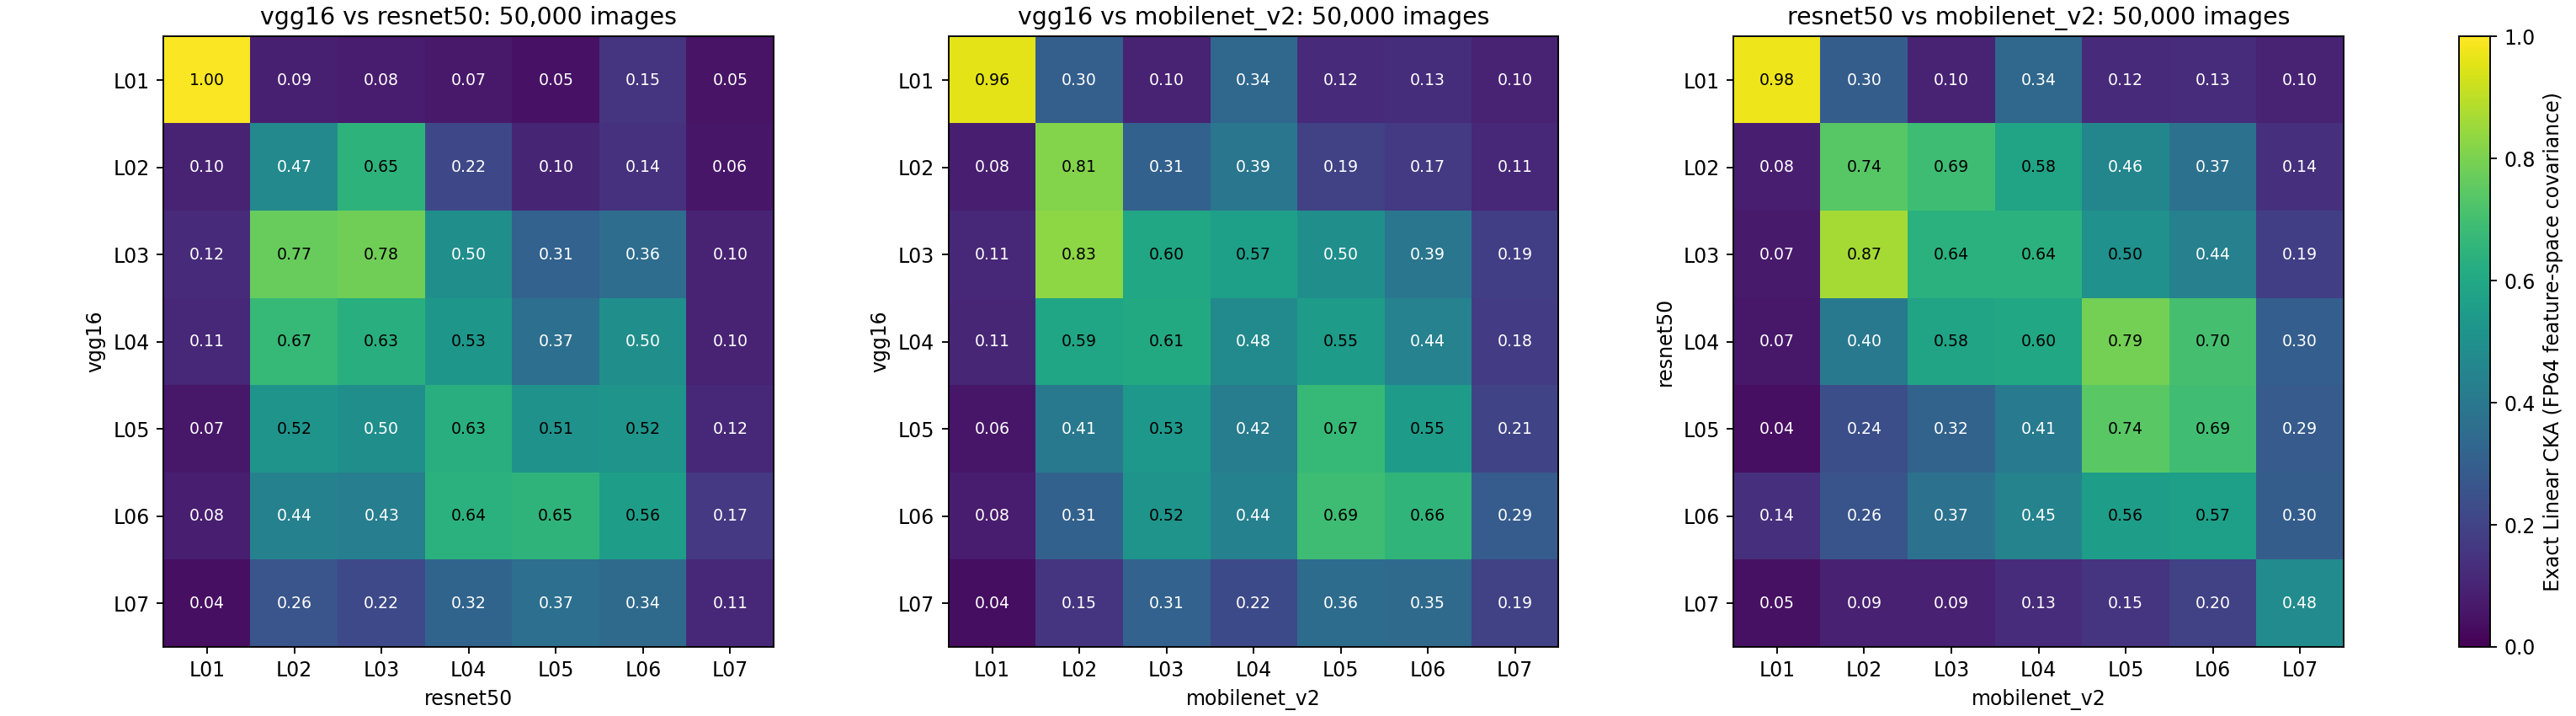

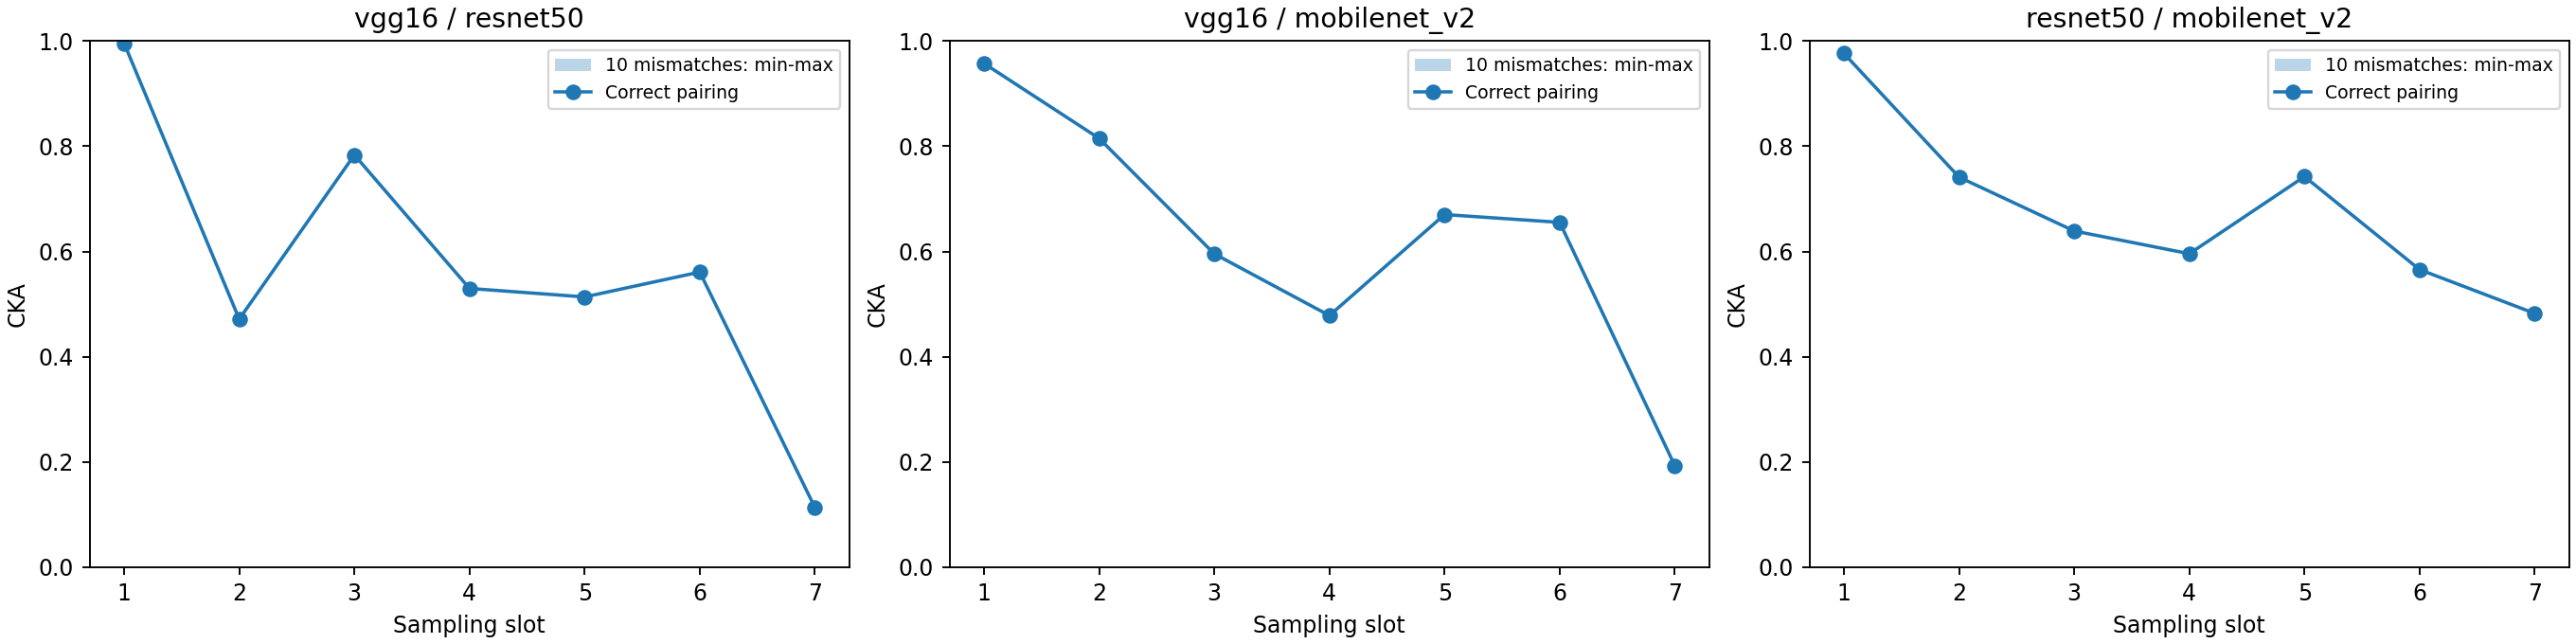

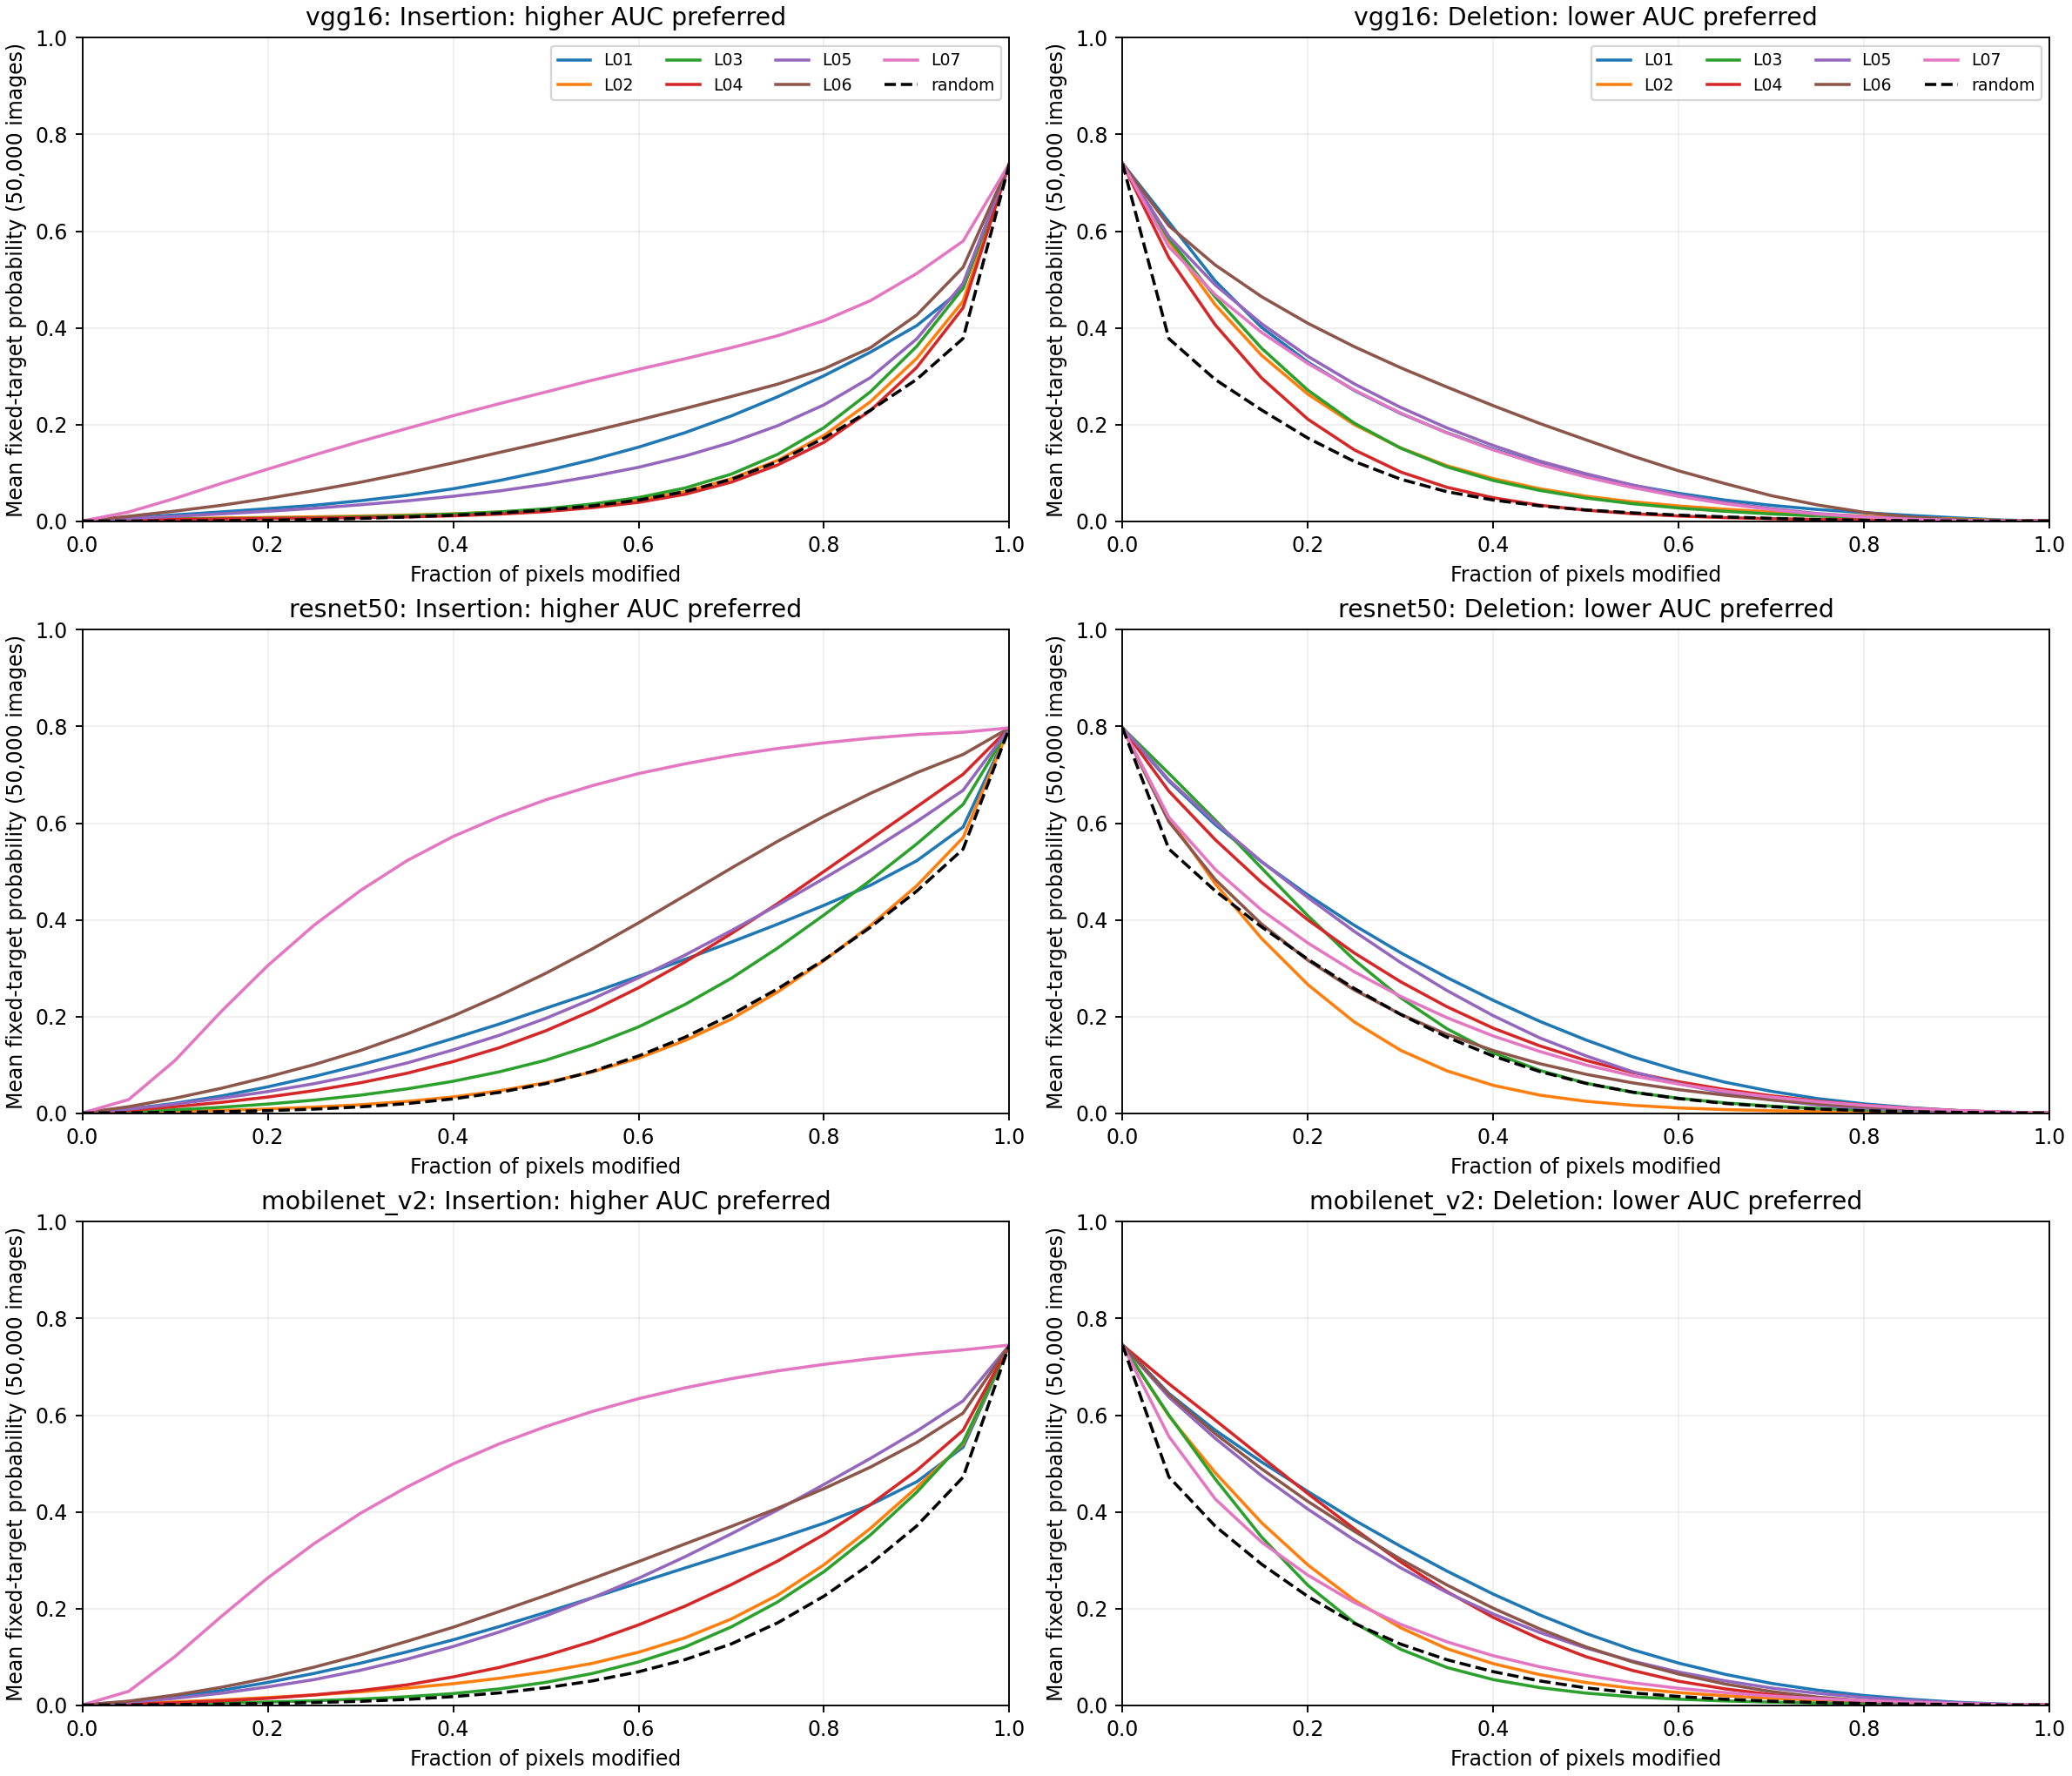

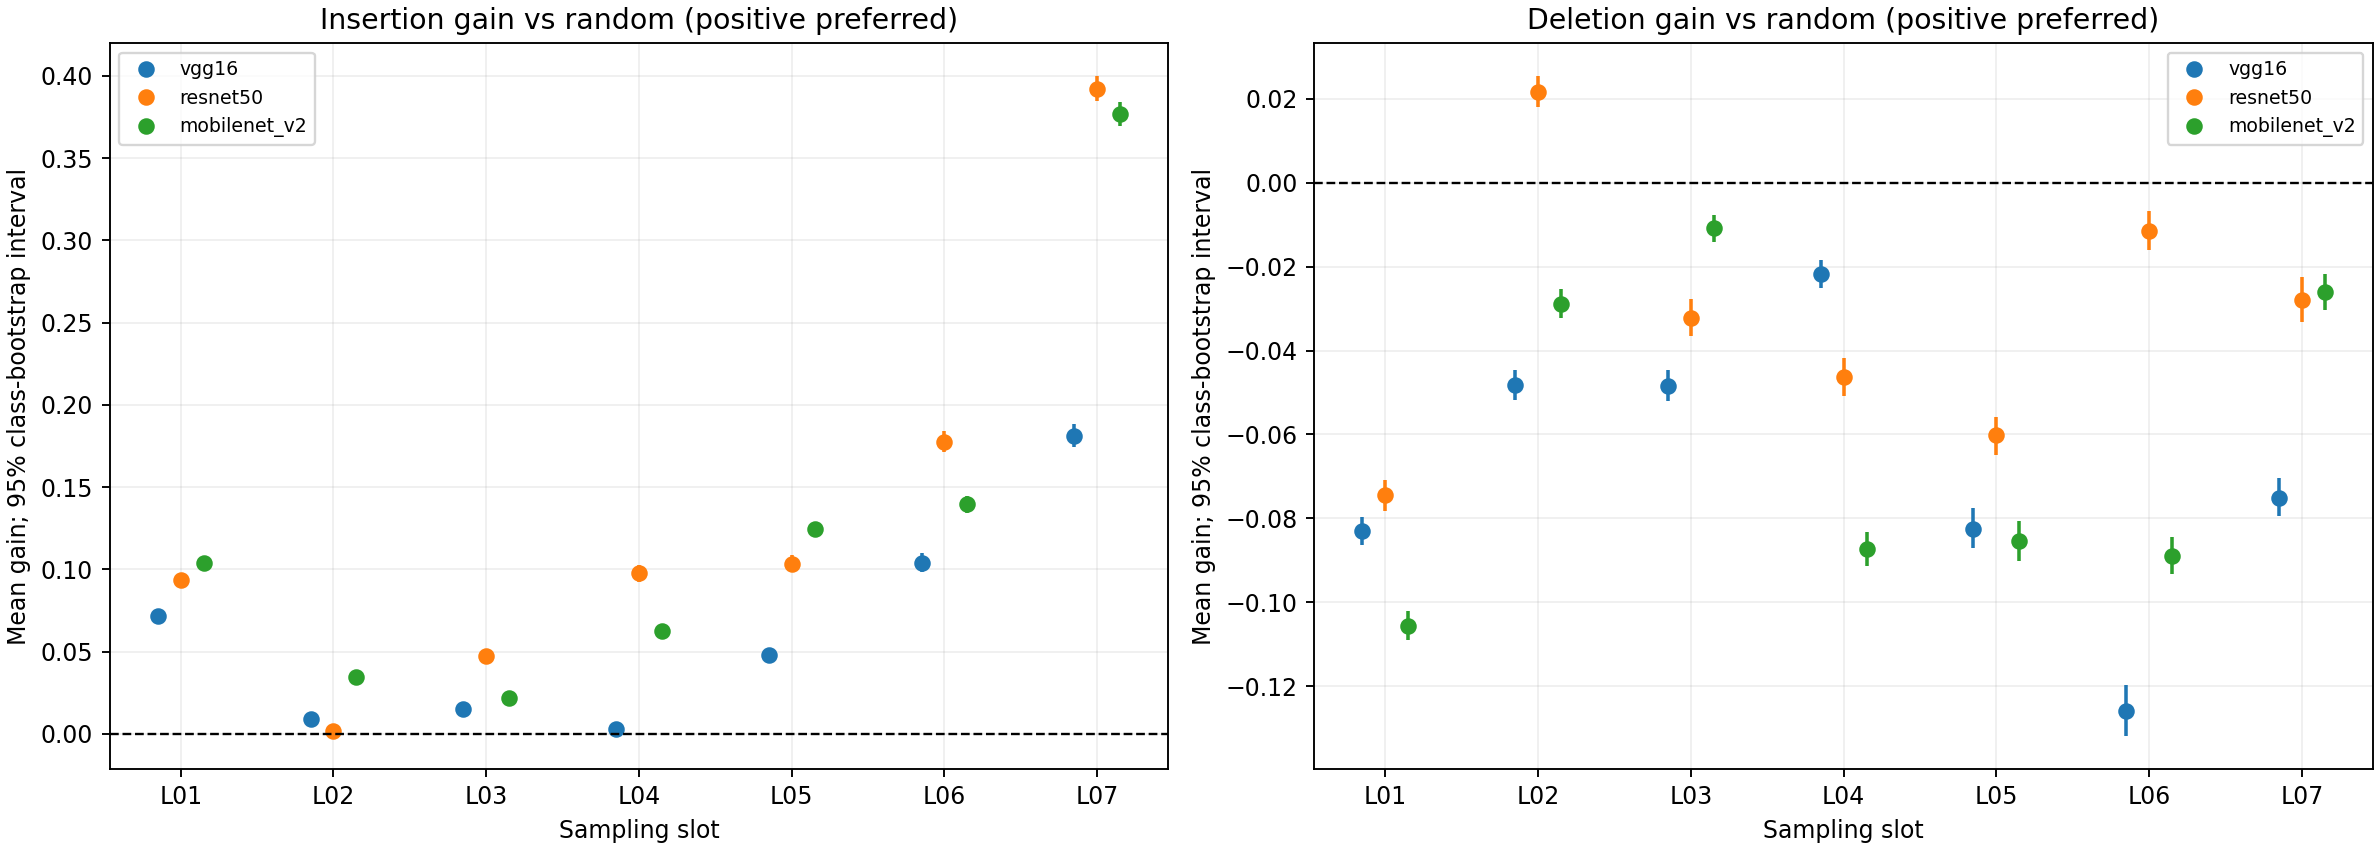

In [9]:
from IPython.display import display,Markdown,Image as DisplayImage
cka=pd.read_csv(FULL/'results/cka_main.csv')
id_table=pd.read_csv(FULL/'results/id_summary.csv')
assert len(cka)==147 and len(id_table)==24
display(cka)
display(id_table)
for figure in ['cka_full_matrices.png','cka_full_controls.png','id_full_curves.png','id_full_gains.png']:
    display(DisplayImage(filename=str(FULL/'figures'/figure)))


## 7. Interpretation and limitations

The text below is generated from measured values. Full validation removes the pilot's coverage limitation but does not remove GAP information loss,
operation-role differences, baseline effects, calibration differences, or out-of-distribution masking.
Report CKA and both perturbation directions separately when rankings disagree. Post-hoc maxima are descriptive, not prespecified tests.


In [10]:
lines=['# Full-validation interpretation']
for (a,b),table in cka.groupby(['model_a','model_b'],sort=False):
    matrix=table.pivot(index='slot_a',columns='slot_b',values='cka').to_numpy()
    i,j=np.unravel_index(np.argmax(matrix),matrix.shape)
    diagonal=np.diag(matrix)
    lines.append(f'**{a} / {b}**: maximum L{i+1:02d}—L{j+1:02d}, CKA={matrix[i,j]:.4f}; same-slot early/middle/late means are {diagonal[:2].mean():.4f}/{diagonal[2:5].mean():.4f}/{diagonal[5:].mean():.4f}. Group means do not establish monotonic depth trends or semantic alignment.')
for name in SPECS:
    sub=id_table[(id_table.model==name)&(id_table.method!='random')]
    random_row=id_table[(id_table.model==name)&(id_table.method=='random')].iloc[0]
    ins=sub.loc[sub.insertion_auc_mean.idxmax()];dele=sub.loc[sub.deletion_auc_mean.idxmin()]
    lines.append(f'**{name}**: highest insertion {ins.method}={ins.insertion_auc_mean:.4f}, random={random_row.insertion_auc_mean:.4f}; lowest deletion {dele.method}={dele.deletion_auc_mean:.4f}, random={random_row.deletion_auc_mean:.4f}. {int((sub.ins_gain_ci_low>0).sum())}/{int((sub.del_gain_ci_low>0).sum())} layers have entirely positive gain intervals. All {int(sub.all_zero_maps.sum())} zero maps remain evaluated.')
lines.extend(['Global color/brightness may dominate high early GAP similarity. No color ablation was performed, so identical edge detectors are not established.',
 'Insertion effectiveness does not guarantee deletion effectiveness. Random scattered masking may disrupt texture more than contiguous masking, but this proposed mechanism was not tested.',
 'Complete-validation metrics describe a fixed finite benchmark. Class-bootstrap intervals concern class-composition sensitivity and do not automatically generalize to all future images or establish causal explanations.',
 'FP16 calibration on 24 images is empirical; other masks can have larger errors. Precision measurements and FP32 fallback counts appear in the audit.'])
display(Markdown('\n\n'.join(lines)))


# Full-validation interpretation

**vgg16 / resnet50**: maximum L01—L01, CKA=0.9958; same-slot early/middle/late means are 0.7336/0.6089/0.3372. Group means do not establish monotonic depth trends or semantic alignment.

**vgg16 / mobilenet_v2**: maximum L01—L01, CKA=0.9573; same-slot early/middle/late means are 0.8861/0.5813/0.4241. Group means do not establish monotonic depth trends or semantic alignment.

**resnet50 / mobilenet_v2**: maximum L01—L01, CKA=0.9763; same-slot early/middle/late means are 0.8587/0.6590/0.5240. Group means do not establish monotonic depth trends or semantic alignment.

**vgg16**: highest insertion L07=0.2749, random=0.0936; lowest deletion L04=0.1154, random=0.0936. 7/0 layers have entirely positive gain intervals. All 221 zero maps remain evaluated.

**resnet50**: highest insertion L07=0.5485, random=0.1562; lowest deletion L02=0.1347, random=0.1564. 6/1 layers have entirely positive gain intervals. All 260 zero maps remain evaluated.

**mobilenet_v2**: highest insertion L07=0.4949, random=0.1182; lowest deletion L03=0.1290, random=0.1181. 7/0 layers have entirely positive gain intervals. All 4219 zero maps remain evaluated.

Global color/brightness may dominate high early GAP similarity. No color ablation was performed, so identical edge detectors are not established.

Insertion effectiveness does not guarantee deletion effectiveness. Random scattered masking may disrupt texture more than contiguous masking, but this proposed mechanism was not tested.

Complete-validation metrics describe a fixed finite benchmark. Class-bootstrap intervals concern class-composition sensitivity and do not automatically generalize to all future images or establish causal explanations.

FP16 calibration on 24 images is empirical; other masks can have larger errors. Precision measurements and FP32 fallback counts appear in the audit.

## 8. Sources, submission, and terminology

A cache stores reusable values; a manifest records sources; a checkpoint stores progress; a seed fixes random initialization; AUC is area under a curve; logits are unnormalized scores.
Linear probes train additional readouts, while this study does not train CNNs. Activation maximization synthesizes inputs, Grad-CAM highlights spatial responses, and CKA compares representation geometry.

The study follows the team's ImageNet model configuration. The earlier 1,000-image CKA / 100-image I/D remains a pilot and is not mixed with full-data scores.
This notebook is the primary submission. Both languages use identical scientific code/protocols and include saved outputs. Rerunning requires authorized access or project caches.
References: [CKA](https://proceedings.mlr.press/v97/kornblith19a.html), [Grad-CAM](https://arxiv.org/abs/1610.02391), [RISE](https://arxiv.org/abs/1806.07421), [ImageNet](https://huggingface.co/datasets/ILSVRC/imagenet-1k).
